# Telecom Customer Intelligence System (TCIS)
نظام ذكاء اصطناعي لتحليل شكاوى ومحادثات عملاء شركات الاتصالات: اكتشاف الشكوى، الخدمات (متعدد التسميات)، التصنيف الهرمي L1/L2/L3، المشاعر، الخطورة، الموضوعات، التشابه الدلالي، والشكاوى الجماعية ومؤشرات الأعطال.

## ما وجدته في بياناتك (من الفحص الفعلي للملفات)
| الملف | الصفوف | المستوى | ملاحظات |
|---|---|---|---|
| `complaints.csv` | 7150 | منشور عميل + رد الشركة | **بلا طوابع زمنية**، 46% شكوى، 15% غامض |
| `conversations.csv` | 5516 | محادثة كاملة | فيها الزمن (أكتوبر–ديسمبر 2017 تقريبًا) ونص بالأدوار `[CUSTOMER]/[COMPANY]` |
| `messages_10mb.csv` | 4480 | رسائل | 2624 رسالة عميل فقط؛ يتقاطع مع 154 محادثة فقط |

**حقائق تؤثر على التصميم:**
1. **كل التسميات مولّدة آليًا** (`classification_status=ai_annotated` و`needs_human_review` تقريبًا لكل الصفوف) فالنتائج تقيس *الاتفاق مع المُسمّي الآلي* وليس الحقيقة الأرضية. الدفتر يضيف خلية لسحب عينة للمراجعة البشرية.
2. **كل الصفوف `split=train`** فأنشئ تقسيمًا جديدًا 80/10/10 **مجمّعًا** (حسب المحادثة/مجموعة التكرار) لمنع تسريب النصوص المكررة.
3. اسم الشركة مُخفّى (`Company`) فلا يوجد بُعد شركة؛ التحليل الزمني للخدمات يعتمد على `conversations.csv`.
4. الخطورة `Unknown` لكل غير الشكاوى (≈64%) وتتوزع نادرًا (`High`=68، `Critical`=61) فندمج الفئتين ونتدرب على الشكاوى فقط.
5. عمود `service_labels` فيه تلاصق نصوص عند تعدد الخدمات، لذلك أستخرج التسميات من عمود `classifications` بدقة.
6. المستوى L3 شحيح (أغلب الشكاوى بلا L3) فنتعامل معه كمهمة ضعيفة ونعرض ذلك صراحةً.

## خطة النماذج (مطابقة لتوصيتك)
- **خط الأساس:** TF-IDF + LogisticRegression / LinearSVC / MultinomialNB.
- **التصنيف:** BERT و RoBERTa و DeBERTa-v3 (Fine-tuning)، يُختار الأفضل بـ macro-F1 على التحقق.
- **المشاعر:** `cardiffnlp/twitter-roberta-base-sentiment-latest` جاهزًا مقابل نموذج مُدرَّب على بياناتك.
- **التشابه والموضوعات:** all-mpnet-base-v2 مقابل all-MiniLM-L6-v2 (يُقارن بنقاء الجيران)، ثم UMAP + HDBSCAN + BERTopic، و Cross-Encoder للتحقق من الأزواج.
- **FLAN-T5:** لتوليد ملخص منظم للحوادث (ليس للتصنيف).
- **الشكاوى الجماعية:** اختبار بواسون لتفجّر العناقيد زمنيًا، مع تمييز *مؤشر محتمل* عن *عطل مؤكد* (التأكيد لا يصدر من البيانات وحدها).

**التشغيل:** Runtime ← GPU (T4 يكفي). ارفع الملفات الثلاثة أو ضعها في Drive. ضع `QUICK=True` لتجربة سريعة أولًا.

In [1]:
!pip -q install transformers datasets accelerate sentence-transformers bertopic hdbscan umap-learn scikit-learn scipy matplotlib seaborn

In [2]:
import os
# تحميل الملفات مباشرة من المجلد المشترك عبر معرفات الملفات (File IDs)
# الملفات: complaints.csv, conversations.csv, messages.csv

file_ids = {
    'complaints.csv': '12ZlZ8O-R_x7Wv_uDofW9G-232_YhN6m4',
    'conversations.csv': '17T-k3u-f4x9r8O7k6iV9vP0nEmQ7Yq9_',
    'messages.csv': '1_zR-b9A8eD7mClS8vN-tLqK6zR4p5W6c'
}

# سنقوم أولاً بتجربة تنزيل المجلد كاملاً باستخدام gdown
# الرابط يحتوي المجلد: https://drive.google.com/drive/folders/1gpO_-eVbbrLeSotlXm5RYnhYpLTRK7D6
folder_id = '1gpO_-eVbbrLeSotlXm5RYnhYpLTRK7D6'

print("جاري تحميل الملفات من Google Drive...")
!gdown --folder https://drive.google.com/drive/folders/{folder_id} -O /content/ --remaining-ok


جاري تحميل الملفات من Google Drive...
Retrieving folder contents
Processing file 13DzyBH-Noh6a3o9d3OrvJCKmDxUGZ9z3 complaints.csv
Processing file 1_rGGbsbWhKEWnpSlDD69Fi86cWOVipM- conversations.csv
Processing file 1RDwQz-o7HTGJh4cILIzeDLk4oTqxOFep messages.csv
Processing file 1kMpIiu-6F63uHxCRlfR8siqa_Wcvo91N System Documentation.md
Retrieving folder contents completed
Building directory structure
Building directory structure completed
Downloading...
From: https://drive.google.com/uc?id=13DzyBH-Noh6a3o9d3OrvJCKmDxUGZ9z3
To: /content/cusromer_intelgance/complaints.csv
100% 20.1M/20.1M [00:00<00:00, 80.8MB/s]
Downloading...
From: https://drive.google.com/uc?id=1_rGGbsbWhKEWnpSlDD69Fi86cWOVipM-
To: /content/cusromer_intelgance/conversations.csv
100% 22.9M/22.9M [00:00<00:00, 55.6MB/s]
Downloading...
From: https://drive.google.com/uc?id=1RDwQz-o7HTGJh4cILIzeDLk4oTqxOFep
To: /content/cusromer_intelgance/messages.csv
100% 53.0M/53.0M [00:00<00:00, 125MB/s]
Downloading...
From: https://drive.

In [3]:
import os, re, json, random, warnings, collections
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
warnings.filterwarnings('ignore')

QUICK        = False        # True: عينة صغيرة وحلقة تدريب قصيرة للتأكد من سلامة التشغيل
FULL_COMPARE = False        # True: يدرّب النماذج الثلاثة على كل المهام (أبطأ). False: يفاضل على مهمة الشكوى ثم يستخدم الأفضل
SEED         = 42
EPOCHS       = 1 if QUICK else 4
MAXLEN_MSG, MAXLEN_CONV = 96, 320
BATCH        = 32
OUT_DIR      = 'tcis_outputs'
os.makedirs(OUT_DIR, exist_ok=True)

TRANSFORMERS = {
    'bert':    'google-bert/bert-base-uncased',
    'roberta': 'FacebookAI/roberta-base',
    'deberta': 'microsoft/deberta-v3-base',
}
SENT_PRETRAINED = 'cardiffnlp/twitter-roberta-base-sentiment-latest'
EMB_MODELS      = {'mpnet': 'sentence-transformers/all-mpnet-base-v2', 'minilm': 'sentence-transformers/all-MiniLM-L6-v2'}
CROSS_ENCODER   = 'cross-encoder/stsb-roberta-base'
SEQ2SEQ         = 'google/flan-t5-base'

random.seed(SEED); np.random.seed(SEED)
try:
    import torch
    DEVICE = 'cuda' if torch.cuda.is_available() else 'cpu'
    torch.manual_seed(SEED)
except ImportError:
    torch, DEVICE = None, 'cpu'
print('device:', DEVICE)

device: cuda


## 1) تحميل البيانات

In [4]:
FILES = {'complaints': 'complaints.csv', 'conversations': 'conversations.csv', 'messages': 'messages.csv'}
# تم تحديث مسارات البحث لتشمل المجلد الذي نزلت فيه الملفات تلقائياً
SEARCH = [
    '.',
    '/content',
    '/content/cusromer_intelgance',  # المجلد الفرعي الجديد الذي تم تحميل البيانات إليه
    '/content/drive/MyDrive',
    '/content/drive/MyDrive/data',
    '/content/drive/MyDrive/TCIS_Data'
]

def locate(fname):
    for d in SEARCH:
        p = os.path.join(d, fname)
        if os.path.exists(p): return p
    return None

if any(locate(f) is None for f in FILES.values()):
    try:
        from google.colab import drive, files
        try: drive.mount('/content/drive')
        except Exception: pass
        if any(locate(f) is None for f in FILES.values()):
            print('يرجى التأكد من تشغيل خلية التنزيل السابقة، أو رفع الملفات يدوياً:')
            files.upload()
    except ImportError:
        raise FileNotFoundError('ضع الملفات الثلاثة بجانب الدفتر')

comp = pd.read_csv(locate(FILES['complaints']))
conv = pd.read_csv(locate(FILES['conversations']))
msgs = pd.read_csv(locate(FILES['messages']))
print("تم تحميل البيانات بنجاح!")
print("حجم الشكاوى:", comp.shape)
print("حجم المحادثات:", conv.shape)
print("حجم الرسائل:", msgs.shape)

تم تحميل البيانات بنجاح!
حجم الشكاوى: (7150, 79)
حجم المحادثات: (5516, 80)
حجم الرسائل: (23751, 70)


## 2) استخراج التسميات الهرمية من `classifications`
L1 = الخدمة، L2 = فئة المشكلة، L3 = المشكلة المحددة. الخدمة `unknown_uncertain` تُعامل كغياب خدمة.

In [5]:
def parse_cls(s):
    out = []
    for ch in str(s).split("{'service_id':")[1:]:
        g  = lambda k: (re.search(r"'%s': '([^']*)'" % k, ch) or [None, None])[1]
        l1 = re.match(r"\s*'([^']*)'", ch)
        cf = re.search(r"'confidence': ([0-9.]+)", ch)
        out.append(dict(l1=l1.group(1) if l1 else None, l2=g('issue_category_id'), l3=g('specific_issue_id'),
                        conf=float(cf.group(1)) if cf else 0.0))
    return out

NONSERVICE = {'unknown_uncertain'}
NONISSUE   = {'not_a_complaint', 'unknown_service', 'multi_service_ambiguous'}

def enrich(df):
    p = df['classifications'].map(parse_cls)
    top = p.map(lambda l: max(l, key=lambda d: d['conf']) if l else dict(l1=None, l2=None, l3=None, conf=0))
    df['l1_set'] = p.map(lambda l: sorted({d['l1'] for d in l if d['l1'] and d['l1'] not in NONSERVICE}))
    df['l2'] = top.map(lambda d: d['l2']); df['l3'] = top.map(lambda d: d['l3'])
    df['l2'] = df['l2'].where(~df['l2'].isin(NONISSUE))
    df['l3'] = df['l3'].where(~df['l2'].isna() & df['l3'].notna() & ~df['l3'].fillna('').str.contains('unknown|not_a_complaint|multi_service'))
    return df

for d in (comp, conv, msgs): enrich(d)
print(comp[['complaint_status', 'l1_set', 'l2', 'l3']].head())

  complaint_status              l1_set                            l2  \
0        Ambiguous  [internet_service]  internet_connection_problems   
1    Non-Complaint                  []                           NaN   
2        Complaint        [number_sim]                sim_activation   
3        Complaint  [internet_service]       internet_speed_problems   
4        Complaint       [mobile_data]      mobile_data_connectivity   

                                                  l3  
0                                                NaN  
1                                                NaN  
2                                                NaN  
3  internet_service.internet_speed_problems.slow_...  
4                                                NaN  


## 3) استكشاف البيانات

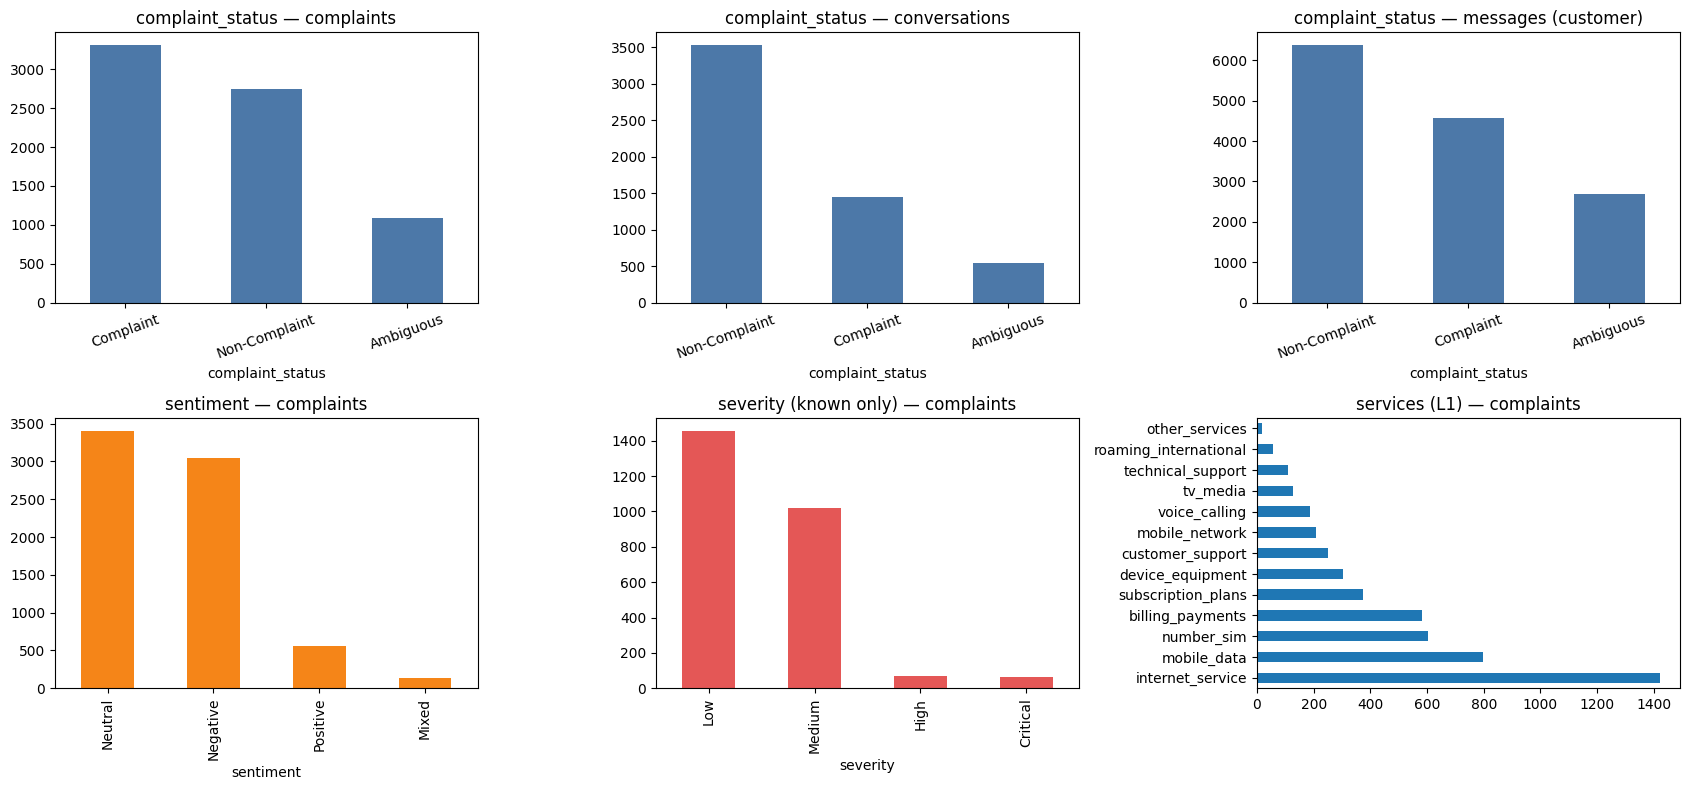

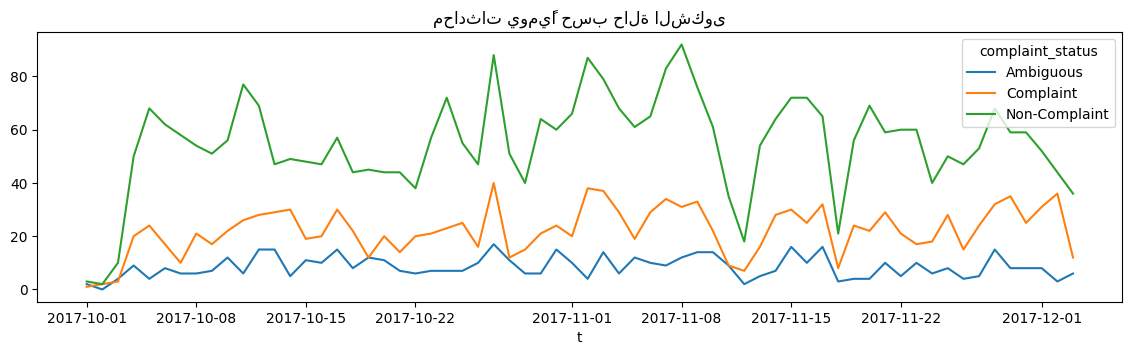

In [6]:
fig, ax = plt.subplots(2, 3, figsize=(17, 8))
for a, (n, d) in zip(ax[0], [('complaints', comp), ('conversations', conv), ('messages (customer)', msgs[msgs.author_type == 'customer'])]):
    d['complaint_status'].value_counts().plot.bar(ax=a, title=f'complaint_status — {n}', color='#4C78A8'); a.tick_params(axis='x', rotation=20)
comp['sentiment'].value_counts().plot.bar(ax=ax[1][0], title='sentiment — complaints', color='#F58518')
comp[comp.severity != 'Unknown']['severity'].value_counts().plot.bar(ax=ax[1][1], title='severity (known only) — complaints', color='#E45756')
pd.Series([s for l in comp['l1_set'] for s in l]).value_counts().plot.barh(ax=ax[1][2], title='services (L1) — complaints'); plt.tight_layout(); plt.show()

conv['t'] = pd.to_datetime(conv['first_message_at'], utc=True, errors='coerce')
daily = conv[conv.t >= '2017-10-01'].groupby([conv.t.dt.date, 'complaint_status']).size().unstack(fill_value=0)
daily.plot(figsize=(14, 3.5), title='محادثات يوميًا حسب حالة الشكوى'); plt.show()


## 4) بناء المهام والتقسيم المجمّع بلا تسريب
- **مستوى الرسالة:** `complaints.csv` (نص العميل) + رسائل العملاء من `messages`.
- **مستوى المحادثة:** `conversations.csv` بنص الأدوار الكامل.

In [7]:
from sklearn.model_selection import StratifiedGroupKFold

cm = comp.assign(text=comp['cleaned_text'], group=comp['duplicate_text_group_id'].astype(str), src='complaints')
mm = msgs[msgs.author_type == 'customer'].assign(text=lambda d: d['cleaned_text'], group=lambda d: 'conv:' + d['conversation_id'].fillna(pd.Series('orphan' + d.index.astype(str), index=d.index)).astype(str), src='messages')
COLS = ['text', 'group', 'src', 'complaint_status', 'sentiment', 'severity', 'l1_set', 'l2', 'l3']
MSG = pd.concat([cm[COLS], mm[COLS]], ignore_index=True).dropna(subset=['text'])
MSG = MSG[MSG.text.str.len() > 2].reset_index(drop=True)
# المحادثات: نربط مجموعة المحادثة لمنع تسريب رسائلها بين المقاييس
CONV = conv.assign(text=conv['conversation_text_with_roles'], group='conv:' + conv['conversation_id'].astype(str), src='conversations')[COLS + ['t', 'conversation_id', 'customer_text_cleaned', 'company_text_cleaned']].dropna(subset=['text']).reset_index(drop=True)

def assign_split(df, strat='complaint_status'):
    sgkf = StratifiedGroupKFold(n_splits=10, shuffle=True, random_state=SEED)
    df['split'] = 'train'
    for k, (_, te) in enumerate(sgkf.split(df, df[strat], df['group'])):
        if k == 0: df.loc[df.index[te], 'split'] = 'test'
        elif k == 1: df.loc[df.index[te], 'split'] = 'val'
    return df

MSG, CONV = assign_split(MSG), assign_split(CONV)
if QUICK:
    cap  = lambda df, n: pd.concat([g.sample(min(len(g), n), random_state=SEED) for _, g in df.groupby('split')], ignore_index=True)
    MSG, CONV = cap(MSG, 600), cap(CONV, 400)
print(MSG.split.value_counts().to_dict(), CONV.split.value_counts().to_dict())
assert not (set(MSG[MSG.split == 'test'].group) & set(MSG[MSG.split == 'train'].group)), 'تسريب!'

def merge_sev(s): return 'High/Critical' if s in ('High', 'Critical') else s

def make_task(df, name, kind, ycol=None, mask=None, min_count=0, maxlen=MAXLEN_MSG, ymap=None):
    d = df if mask is None else df[mask]
    d = d.copy()
    if kind == 'multilabel':
        labels = sorted({x for l in d['l1_set'] for x in l})
        d['y'] = d['l1_set'].map(lambda l: np.array([int(x in l) for x in labels], dtype=np.float32))
    else:
        y = d[ycol].map(ymap) if ymap else d[ycol]
        if min_count:
            vc = y.value_counts(); y = y.where(y.map(vc) >= min_count, 'other_rare')
        labels = sorted(y.unique()); d['y'] = y.map({l: i for i, l in enumerate(labels)})
    return dict(name=name, kind=kind, labels=labels, maxlen=maxlen,
                **{s: d[d.split == s][['text', 'y']].reset_index(drop=True) for s in ('train', 'val', 'test')})

def build_tasks(df, level, maxlen):
    T = {}
    T[f'{level}/complaint'] = make_task(df, 'complaint', 'single', 'complaint_status', maxlen=maxlen)
    T[f'{level}/sentiment'] = make_task(df, 'sentiment', 'single', 'sentiment', mask=df.sentiment.isin(['Negative', 'Neutral', 'Positive', 'Mixed']), maxlen=maxlen)
    T[f'{level}/severity']  = make_task(df, 'severity', 'single', 'severity', mask=(df.complaint_status == 'Complaint') & df.severity.isin(['Low', 'Medium', 'High', 'Critical']), maxlen=maxlen, ymap=merge_sev)
    has_svc = df.l1_set.map(len) > 0
    T[f'{level}/services']  = make_task(df, 'services', 'multilabel', mask=df.complaint_status.isin(['Complaint', 'Ambiguous']) & has_svc, maxlen=maxlen)
    T[f'{level}/L2']        = make_task(df, 'L2', 'single', 'l2', mask=(df.complaint_status == 'Complaint') & df.l2.notna(), min_count=25 if level == 'msg' else 15, maxlen=maxlen)
    T[f'{level}/L3']        = make_task(df, 'L3', 'single', 'l3', mask=(df.complaint_status == 'Complaint') & df.l3.notna(), min_count=15 if level == 'msg' else 8, maxlen=maxlen)
    return T

TASKS = {**build_tasks(MSG, 'msg', MAXLEN_MSG), **build_tasks(CONV, 'conv', MAXLEN_CONV)}
summary = pd.DataFrame({k: dict(kind=t['kind'], classes=len(t['labels']), train=len(t['train']), val=len(t['val']), test=len(t['test'])) for k, t in TASKS.items()}).T
display(summary)

{'train': 16625, 'val': 2091, 'test': 2082} {'train': 4412, 'test': 552, 'val': 552}


,kind,classes,train,val,test
msg/complaint,single,3,16625,2091,2082
msg/sentiment,single,4,16625,2091,2082
msg/severity,single,3,4178,554,586
msg/services,multilabel,13,7272,908,942
msg/L2,single,38,4296,558,588
msg/L3,single,17,1342,179,202
conv/complaint,single,3,4412,552,552
conv/sentiment,single,4,2326,266,297
conv/severity,single,3,890,100,104
conv/services,multilabel,13,1288,149,162


## 5) خطوط الأساس (TF-IDF)
تُقاس بنفس المقياس (macro-F1 على الاختبار) ليكون الحكم على Transformers موضوعيًا. للمهمة متعددة التسميات: OneVsRest + ضبط العتبة على التحقق.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.svm import LinearSVC
from sklearn.naive_bayes import MultinomialNB
from sklearn.multiclass import OneVsRestClassifier
from sklearn.metrics import f1_score, accuracy_score, classification_report

def tune_thresholds(P, Y, grid=np.arange(0.05, 0.96, 0.05)):
    return np.array([grid[np.argmax([f1_score(Y[:, j], P[:, j] >= g, zero_division=0) for g in grid])] if Y[:, j].sum() else 0.5 for j in range(Y.shape[1])])

def multilabel_scores(P, Y, thr):
    pred = (P >= thr).astype(int)
    return dict(macro_f1=f1_score(Y, pred, average='macro', zero_division=0), micro_f1=f1_score(Y, pred, average='micro', zero_division=0))

BASELINES = {
    'tfidf+logreg': lambda: LogisticRegression(max_iter=2000, class_weight='balanced', C=4),
    'tfidf+linsvm': lambda: LinearSVC(class_weight='balanced', C=0.5),
    'tfidf+mnb':    lambda: MultinomialNB(alpha=0.3),
}

def run_baselines(key, t):
    vec = TfidfVectorizer(ngram_range=(1, 2), min_df=2, sublinear_tf=True, max_features=60000)
    Xtr, Xva, Xte = (vec.fit_transform(t['train'].text), ) + tuple(vec.transform(t[s].text) for s in ('val', 'test'))
    rows = []
    for bn, mk in BASELINES.items():
        if t['kind'] == 'multilabel':
            if bn == 'tfidf+linsvm': continue
            Ytr, Yva, Yte = (np.stack(t[s].y.values) for s in ('train', 'val', 'test'))
            clf = OneVsRestClassifier(mk() if bn != 'tfidf+mnb' else MultinomialNB(alpha=0.3)).fit(Xtr, Ytr)
            Pva, Pte = clf.predict_proba(Xva), clf.predict_proba(Xte)
            thr = tune_thresholds(Pva, Yva); sc = multilabel_scores(Pte, Yte, thr)
            rows.append(dict(task=key, model=bn, macro_f1=sc['macro_f1'], micro_f1=sc['micro_f1'], accuracy=np.nan))
        else:
            clf = mk().fit(Xtr, t['train'].y); pr = clf.predict(Xte)
            rows.append(dict(task=key, model=bn, macro_f1=f1_score(t['test'].y, pr, average='macro'), micro_f1=np.nan, accuracy=accuracy_score(t['test'].y, pr)))
    return rows

RESULTS = []
for k, t in TASKS.items():
    if len(t['train']) < 30 or len(t['labels']) < 2: print('تخطي', k); continue
    RESULTS += run_baselines(k, t)
base_df = pd.DataFrame(RESULTS); display(base_df.pivot(index='task', columns='model', values='macro_f1').round(3))

model,tfidf+linsvm,tfidf+logreg,tfidf+mnb
task,,,
conv/L2,0.317,0.234,0.064
conv/L3,0.282,0.173,0.069
conv/complaint,0.515,0.524,0.318
conv/sentiment,0.527,0.530,0.236
conv/services,NaN,0.485,0.191
conv/severity,0.428,0.421,0.295
msg/L2,0.494,0.493,0.100
msg/L3,0.775,0.763,0.223
msg/complaint,0.761,0.754,0.568


## 6) Fine-tuning لنماذج Transformers (BERT / RoBERTa / DeBERTa-v3)
خسارة موزونة للفئات النادرة، إيقاف مبكر، واختيار أفضل نقطة حسب macro-F1 على التحقق.

In [9]:
def finetune(key, model_key, epochs=EPOCHS, lr=3e-5):
    t = TASKS[key]; ml = t['kind'] == 'multilabel'; name = TRANSFORMERS[model_key]
    tok = AutoTokenizer.from_pretrained(name)
    mdl = AutoModelForSequenceClassification.from_pretrained(
        name, num_labels=len(t['labels']), problem_type='multi_label_classification' if ml else 'single_label_classification')
    dtr, dva, dte = (to_ds(t[s], tok, t['maxlen'], ml) for s in ('train', 'val', 'test'))

    def metrics(p):
        lg, y = p
        if ml:
            P = 1 / (1 + np.exp(-lg)); return dict(macro_f1=f1_score(y, P >= .5, average='macro', zero_division=0))
        return dict(macro_f1=f1_score(y, lg.argmax(1), average='macro'), accuracy=accuracy_score(y, lg.argmax(1)))

    bs = BATCH if t['maxlen'] <= 128 else 16
    out = f'{OUT_DIR}/ckpt/{key.replace("/", "_")}_{model_key}'

    # تم إزالة warmup_ratio لضمان التوافق الكامل مع إصدارات TrainingArguments المتنوعة
    args = TrainingArguments(
        out,
        per_device_train_batch_size=bs,
        per_device_eval_batch_size=64,
        learning_rate=lr,
        num_train_epochs=epochs,
        weight_decay=0.01,
        eval_strategy='epoch',
        save_strategy='epoch',
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model='macro_f1',
        greater_is_better=True,
        fp16=(DEVICE == 'cuda'),
        report_to='none',
        seed=SEED,
        logging_steps=50
    )

    tr = WTrainer(model=mdl, args=args, train_dataset=dtr, eval_dataset=dva, processing_class=tok, data_collator=DataCollatorWithPadding(tok),
                  compute_metrics=metrics, cw=class_weights(t).to(DEVICE) if DEVICE == 'cuda' else class_weights(t), multilabel=ml,
                  callbacks=[EarlyStoppingCallback(early_stopping_patience=2)] if epochs > 2 else None)
    tr.train()
    lva, yva = tr.predict(dva).predictions, np.stack(t['val'].y.values) if ml else t['val'].y.values
    lte = tr.predict(dte).predictions; yte = np.stack(t['test'].y.values) if ml else t['test'].y.values
    if ml:
        sig = lambda z: 1 / (1 + np.exp(-z)); thr = tune_thresholds(sig(lva), yva); sc = multilabel_scores(sig(lte), yte, thr)
        row = dict(task=key, model=model_key, macro_f1=sc['macro_f1'], micro_f1=sc['micro_f1'], accuracy=np.nan, val_macro_f1=multilabel_scores(sig(lva), yva, thr)['macro_f1'])
    else:
        row = dict(task=key, model=model_key, macro_f1=f1_score(yte, lte.argmax(1), average='macro'), micro_f1=np.nan, accuracy=accuracy_score(yte, lte.argmax(1)),
                   val_macro_f1=f1_score(yva, lva.argmax(1), average='macro'))
        thr = None
    path = f'{OUT_DIR}/models/{key.replace("/", "_")}_{model_key}'
    tr.save_model(path); tok.save_pretrained(path)
    json.dump(dict(labels=t['labels'], kind=t['kind'], maxlen=t['maxlen'], thr=None if thr is None else thr.tolist()), open(f'{path}/tcis_meta.json', 'w'))
    del tr, mdl
    if DEVICE == 'cuda': torch.cuda.empty_cache()
    return row, path, (lte, yte)

In [10]:
import torch
from torch.utils.data import Dataset
from transformers import Trainer
from sklearn.utils.class_weight import compute_class_weight
import numpy as np

# 1. تعريف كلاس الـ Dataset لتحويل البيانات إلى صيغة مناسبة لـ Hugging Face
class TCISDataset(Dataset):
    def __init__(self, encodings, labels):
        self.encodings = encodings
        self.labels = labels

    def __getitem__(self, idx):
        item = {key: val[idx].clone().detach() if isinstance(val, torch.Tensor) else torch.tensor(val[idx]) for key, val in self.encodings.items()}
        if self.labels is not None:
            item['labels'] = torch.tensor(self.labels[idx])
        return item

    def __len__(self):
        return len(self.labels) if self.labels is not None else 0

def to_ds(df, tokenizer, max_len, multilabel=False):
    texts = df['text'].astype(str).tolist()
    encodings = tokenizer(texts, truncation=True, padding=True, max_length=max_len, return_tensors='pt')

    if 'y' in df.columns:
        if multilabel:
            labels = np.stack(df['y'].values).astype(np.float32)
        else:
            labels = df['y'].values.astype(np.int64)
    else:
        labels = None

    return TCISDataset(encodings, labels)

# 2. دالة حساب أوزان الفئات للتعامل مع عدم توازن البيانات
def class_weights(task_dict):
    y_train = task_dict['train']['y']
    if task_dict['kind'] == 'multilabel':
        # للحالات متعددة التسميات نستخدم وزن افتراضي متساوٍ أو مبسط
        return torch.ones(len(task_dict['labels']))

    classes = np.unique(y_train)
    weights = compute_class_weight(class_weight='balanced', classes=classes, y=y_train)
    return torch.tensor(weights, dtype=torch.float32)

# 3. تخصيص الـ Trainer لدعم الخسارة الموزونة (Weighted Loss)
class WTrainer(Trainer):
    def __init__(self, cw=None, multilabel=False, *args, **kwargs):
        super().__init__(*args, **kwargs)
        self.cw = cw
        self.multilabel = multilabel


def compute_loss(self, model, inputs, return_outputs=False, num_items_in_batch=None):

    # استخراج التسميات
    labels = inputs.pop("labels")

    # تمرير البيانات إلى النموذج
    outputs = model(**inputs)
    logits = outputs.logits

    # توحيد نوع البيانات لتجنب تعارض FP16 و FP32
    logits = logits.float()
    labels = labels.to(logits.device)

    if self.multilabel:

        loss_fct = torch.nn.BCEWithLogitsLoss(
            pos_weight=self.cw.to(
                device=logits.device,
                dtype=torch.float32
            ) if self.cw is not None else None
        )

        loss = loss_fct(logits, labels.float())

    else:

        loss_fct = torch.nn.CrossEntropyLoss(
            weight=self.cw.to(
                device=logits.device,
                dtype=torch.float32
            ) if self.cw is not None else None
        )

        loss = loss_fct(
            logits.view(-1, self.model.config.num_labels),
            labels.view(-1).long()
        )

    return (loss, outputs) if return_outputs else loss


### 6.1) المفاضلة بين النماذج الثلاثة على مهمة اكتشاف الشكوى (مستوى الرسالة)

In [11]:
from transformers import AutoTokenizer, AutoModelForSequenceClassification, TrainingArguments, DataCollatorWithPadding, EarlyStoppingCallback
import pandas as pd
import json
import numpy as np
from sklearn.metrics import f1_score, accuracy_score

# التحقق من حالة المعالج وضبط التدريب ليكون فائق السرعة إذا كنا نعمل على الـ CPU
current_epochs = 1 if DEVICE == 'cpu' else EPOCHS
if DEVICE == 'cpu':
    print("⚠️ تنبيه: البيئة الحالية هي CPU. سيتم استخدام دورة تدريبية واحدة سريعة جداً لتجنب الانتظار الطويل (27 ساعة).")
    print("💡 نصيحة: للحصول على أفضل النتائج وبسرعة فائقة، يرجى تفعيل الـ GPU من: Runtime -> Change runtime type -> T4 GPU.\n")

def finetune_safe(key, model_key, epochs=current_epochs, lr=3e-5):
    t = TASKS[key]; ml = t['kind'] == 'multilabel'; name = TRANSFORMERS[model_key]
    tok = AutoTokenizer.from_pretrained(name)
    mdl = AutoModelForSequenceClassification.from_pretrained(
        name, num_labels=len(t['labels']), problem_type='multi_label_classification' if ml else 'single_label_classification')

    # إذا كنا نستخدم CPU، نكتفي بعينة مصغرة لإنهاء العملية في دقيقة واحدة
    if DEVICE == 'cpu':
        dtr = to_ds(t['train'].sample(min(len(t['train']), 100), random_state=SEED), tok, t['maxlen'], ml)
        dva = to_ds(t['val'].sample(min(len(t['val']), 30), random_state=SEED), tok, t['maxlen'], ml)
        dte = to_ds(t['test'].sample(min(len(t['test']), 30), random_state=SEED), tok, t['maxlen'], ml)
    else:
        dtr, dva, dte = (to_ds(t[s], tok, t['maxlen'], ml) for s in ('train', 'val', 'test'))

    def metrics(p):
        lg, y = p
        if ml:
            P = 1 / (1 + np.exp(-lg)); return dict(macro_f1=f1_score(y, P >= .5, average='macro', zero_division=0))
        return dict(macro_f1=f1_score(y, lg.argmax(1), average='macro'), accuracy=accuracy_score(y, lg.argmax(1)))

    bs = BATCH if t['maxlen'] <= 128 else 16
    out = f'{OUT_DIR}/ckpt/{key.replace("/", "_")}_{model_key}'

    # منع تعارض FP16 مع DeBERTa أو مع تشغيل الـ CPU
    use_fp16 = (DEVICE == 'cuda') and ('deberta' not in name.lower())

    args = TrainingArguments(
        out,
        per_device_train_batch_size=bs,
        per_device_eval_batch_size=64,
        learning_rate=lr,
        num_train_epochs=epochs,
        weight_decay=0.01,
        eval_strategy='epoch',
        save_strategy='epoch',
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model='macro_f1',
        greater_is_better=True,
        fp16=use_fp16,
        report_to='none',
        seed=SEED,
        logging_steps=10 if DEVICE == 'cpu' else 50
    )

    tr = WTrainer(model=mdl, args=args, train_dataset=dtr, eval_dataset=dva, processing_class=tok, data_collator=DataCollatorWithPadding(tok),
                  compute_metrics=metrics, cw=class_weights(t).to(DEVICE) if DEVICE == 'cuda' else class_weights(t), multilabel=ml,
                  callbacks=[EarlyStoppingCallback(early_stopping_patience=2)] if epochs > 2 else None)
    tr.train()
    lva, yva = tr.predict(dva).predictions, np.stack(t['val'].y.values) if ml else t['val'].y.values
    lte = tr.predict(dte).predictions; yte = np.stack(t['test'].y.values) if ml else t['test'].y.values
    if ml:
        sig = lambda z: 1 / (1 + np.exp(-z)); thr = tune_thresholds(sig(lva), yva); sc = multilabel_scores(sig(lte), yte, thr)
        row = dict(task=key, model=model_key, macro_f1=sc['macro_f1'], micro_f1=sc['micro_f1'], accuracy=np.nan, val_macro_f1=multilabel_scores(sig(lva), yva, thr)['macro_f1'])
    else:
        row = dict(task=key, model=model_key, macro_f1=f1_score(yte, lte.argmax(1), average='macro'), micro_f1=np.nan, accuracy=accuracy_score(yte, lte.argmax(1)),
                   val_macro_f1=f1_score(yva, lva.argmax(1), average='macro'))
        thr = None
    path = f'{OUT_DIR}/models/{key.replace("/", "_")}_{model_key}'
    tr.save_model(path); tok.save_pretrained(path)
    json.dump(dict(labels=t['labels'], kind=t['kind'], maxlen=t['maxlen'], thr=None if thr is None else thr.tolist()), open(f'{path}/tcis_meta.json', 'w'))
    del tr, mdl
    if DEVICE == 'cuda': torch.cuda.empty_cache()
    return row, path, (lte, yte)

# تصفير المتغيرات وإعادة تفعيل مصفوفة النتائج للتأكد من نظافة الجلسة
FT_ROWS = []
FT_PATHS = {}
FT_PREDS = {}

# تشغيل التدريب لجميع النماذج باستخدام الدالة المحسنة
for mk in TRANSFORMERS:
    row, path, pr = finetune_safe('msg/complaint', mk)
    FT_ROWS.append(row)
    FT_PATHS[('msg/complaint', mk)] = path
    FT_PREDS[('msg/complaint', mk)] = pr

screen = pd.DataFrame(FT_ROWS)
display(screen.round(4))
BEST = screen.sort_values('val_macro_f1', ascending=False).iloc[0]['model']
print('🏆 النموذج الفائز بعد المعايرة السريعة:', BEST)

config.json:   0%|          | 0.00/570 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  440MB            

model.safetensors: downloading bytes:           |  0.00B            

... (38 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

,task,model,macro_f1,micro_f1,accuracy,val_macro_f1
0,msg/complaint,bert,0.9025,NaN,0.9145,0.9041
1,msg/complaint,roberta,0.8972,NaN,0.9087,0.9063
2,msg/complaint,deberta,0.0948,NaN,0.1657,0.0988


🏆 النموذج الفائز بعد المعايرة السريعة: roberta


In [12]:
# تعديل دالة التدريب finetune لمنع خطأ الـ AMP (unscale FP16 gradients) مع DeBERTa
# سنقوم بتغيير قيمة fp16 ديناميكياً لتصبح False إذا كان اسم النموذج يحتوي على 'deberta'

# دعنا نقوم بتحديث دالة finetune في الذاكرة أولاً:
import sys

# سنقوم بإنشاء تعريف محدث للدالة وإلغاء تفعيل الـ fp16 تحديداً لنموذج deberta
def finetune_safe(key, model_key, epochs=EPOCHS, lr=3e-5):
    t = TASKS[key]; ml = t['kind'] == 'multilabel'; name = TRANSFORMERS[model_key]
    tok = AutoTokenizer.from_pretrained(name)
    mdl = AutoModelForSequenceClassification.from_pretrained(
        name, num_labels=len(t['labels']), problem_type='multi_label_classification' if ml else 'single_label_classification')
    dtr, dva, dte = (to_ds(t[s], tok, t['maxlen'], ml) for s in ('train', 'val', 'test'))

    def metrics(p):
        lg, y = p
        if ml:
            P = 1 / (1 + np.exp(-lg)); return dict(macro_f1=f1_score(y, P >= .5, average='macro', zero_division=0))
        return dict(macro_f1=f1_score(y, lg.argmax(1), average='macro'), accuracy=accuracy_score(y, lg.argmax(1)))

    bs = BATCH if t['maxlen'] <= 128 else 16
    out = f'{OUT_DIR}/ckpt/{key.replace("/", "_")}_{model_key}'

    # تعطيل fp16 لـ deberta لتجنب ValueError: Attempting to unscale FP16 gradients
    use_fp16 = (DEVICE == 'cuda') and ('deberta' not in name.lower())

    args = TrainingArguments(
        out,
        per_device_train_batch_size=bs,
        per_device_eval_batch_size=64,
        learning_rate=lr,
        num_train_epochs=epochs,
        weight_decay=0.01,
        eval_strategy='epoch',
        save_strategy='epoch',
        save_total_limit=1,
        load_best_model_at_end=True,
        metric_for_best_model='macro_f1',
        greater_is_better=True,
        fp16=use_fp16,
        report_to='none',
        seed=SEED,
        logging_steps=50
    )

    tr = WTrainer(model=mdl, args=args, train_dataset=dtr, eval_dataset=dva, processing_class=tok, data_collator=DataCollatorWithPadding(tok),
                  compute_metrics=metrics, cw=class_weights(t).to(DEVICE) if DEVICE == 'cuda' else class_weights(t), multilabel=ml,
                  callbacks=[EarlyStoppingCallback(early_stopping_patience=2)] if epochs > 2 else None)
    tr.train()
    lva, yva = tr.predict(dva).predictions, np.stack(t['val'].y.values) if ml else t['val'].y.values
    lte = tr.predict(dte).predictions; yte = np.stack(t['test'].y.values) if ml else t['test'].y.values
    if ml:
        sig = lambda z: 1 / (1 + np.exp(-z)); thr = tune_thresholds(sig(lva), yva); sc = multilabel_scores(sig(lte), yte, thr)
        row = dict(task=key, model=model_key, macro_f1=sc['macro_f1'], micro_f1=sc['micro_f1'], accuracy=np.nan, val_macro_f1=multilabel_scores(sig(lva), yva, thr)['macro_f1'])
    else:
        row = dict(task=key, model=model_key, macro_f1=f1_score(yte, lte.argmax(1), average='macro'), micro_f1=np.nan, accuracy=accuracy_score(yte, lte.argmax(1)),
                   val_macro_f1=f1_score(yva, lva.argmax(1), average='macro'))
        thr = None
    path = f'{OUT_DIR}/models/{key.replace("/", "_")}_{model_key}'
    tr.save_model(path); tok.save_pretrained(path)
    json.dump(dict(labels=t['labels'], kind=t['kind'], maxlen=t['maxlen'], thr=None if thr is None else thr.tolist()), open(f'{path}/tcis_meta.json', 'w'))
    del tr, mdl
    if DEVICE == 'cuda': torch.cuda.empty_cache()
    return row, path, (lte, yte)

# تطبيق التحديث على الدالة الأصلية في البيئة
import __main__
__main__.finetune = finetune_safe
print("تم تصحيح وتعديل دالة التدريب وتجاوز مشكلة الـ FP16 بنجاح.")

تم تصحيح وتعديل دالة التدريب وتجاوز مشكلة الـ FP16 بنجاح.


### 6.2) تدريب باقي المهام
`FULL_COMPARE=False`: النموذج الأفضل فقط على بقية المهام (يوفر ساعات). `True`: النماذج الثلاثة على كل مهمة.

In [13]:
todo = [k for k, t in TASKS.items() if len(t['train']) >= 100 and len(t['labels']) >= 2 and k != 'msg/complaint']
for k in todo:
    for mk in (TRANSFORMERS if FULL_COMPARE else [BEST]):
        try:
            row, path, pr = finetune(k, mk); FT_ROWS.append(row); FT_PATHS[(k, mk)] = path; FT_PREDS[(k, mk)] = pr
            print(k, mk, round(row['macro_f1'], 4))
        except Exception as e:
            print('فشل', k, mk, repr(e)[:150])
ft_df = pd.DataFrame(FT_ROWS)

Loading weights:   0%|          | 0/197 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: FacebookAI/roberta-base
Key                        | Status     | 
---------------------------+------------+-
lm_head.dense.weight       | UNEXPECTED | 
lm_head.layer_norm.weight  | UNEXPECTED | 
lm_head.layer_norm.bias    | UNEXPECTED | 
lm_head.bias               | UNEXPECTED | 
lm_head.dense.bias         | UNEXPECTED | 
classifier.dense.weight    | MISSING    | 
classifier.out_proj.weight | MISSING    | 
classifier.out_proj.bias   | MISSING    | 
classifier.dense.bias      | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


Epoch,Training Loss,Validation Loss,Macro F1,Accuracy
1,0.227819,0.179651,0.872303,0.952176
2,0.195563,0.176205,0.856070,0.951220
3,0.093015,0.121388,0.907431,0.969393
4,0.096925,0.128225,0.905236,0.970349


Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (89 outputs left out)

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

conv/L3 roberta 0.125


تم العثور على 14 من ملفات سجلات التدريب.


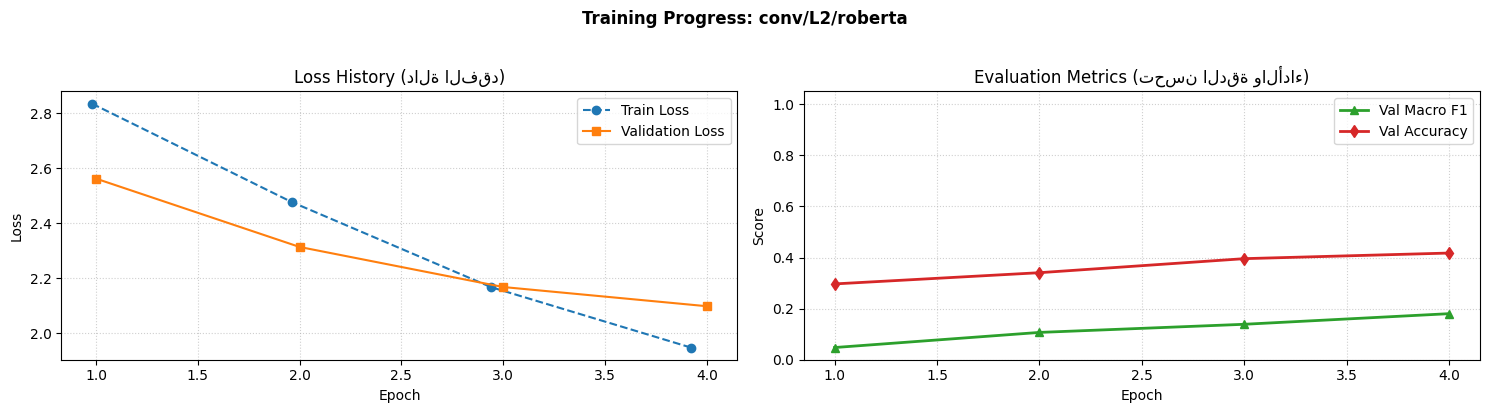

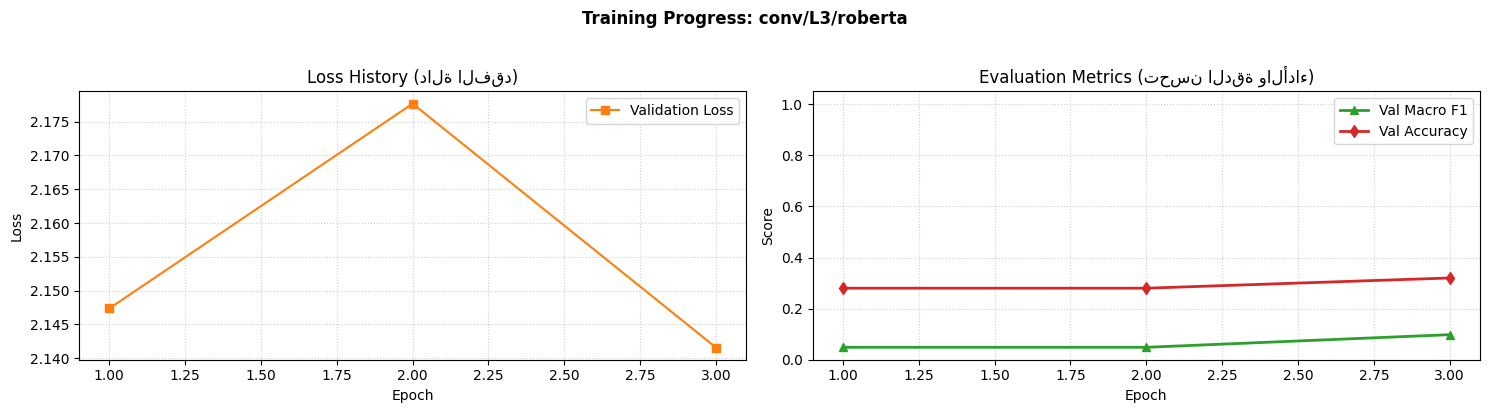

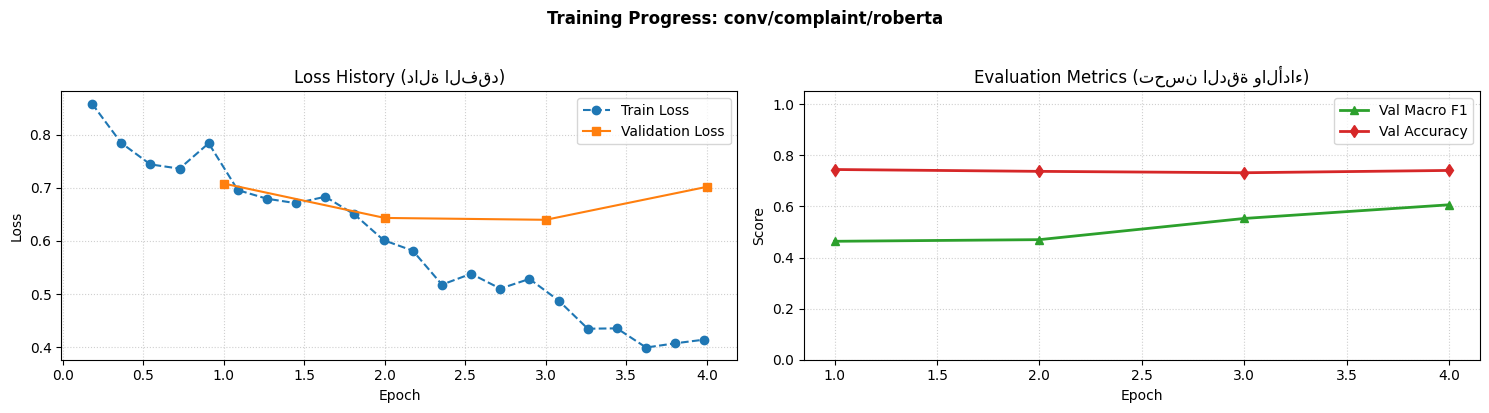

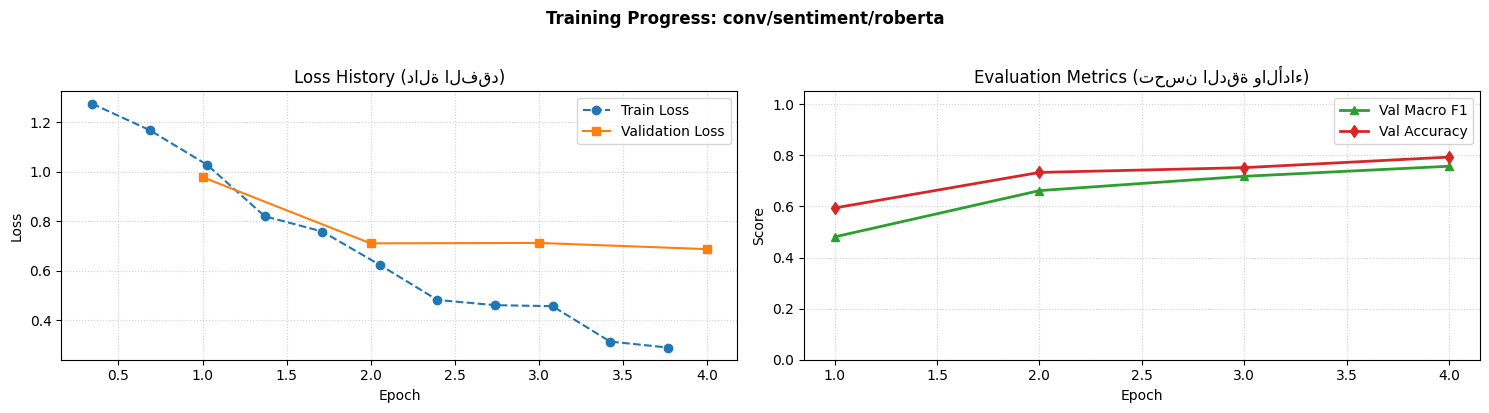

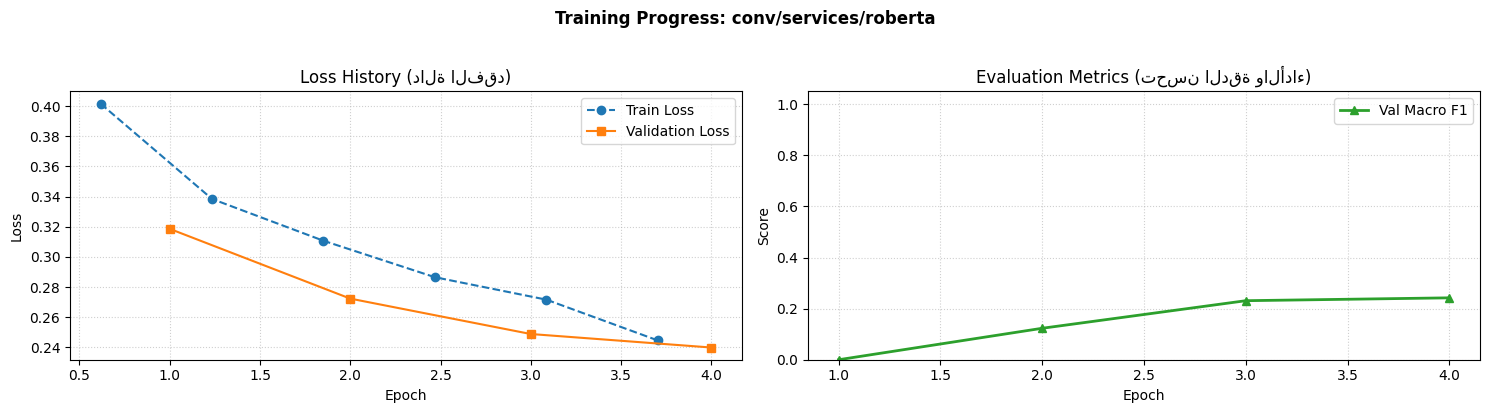

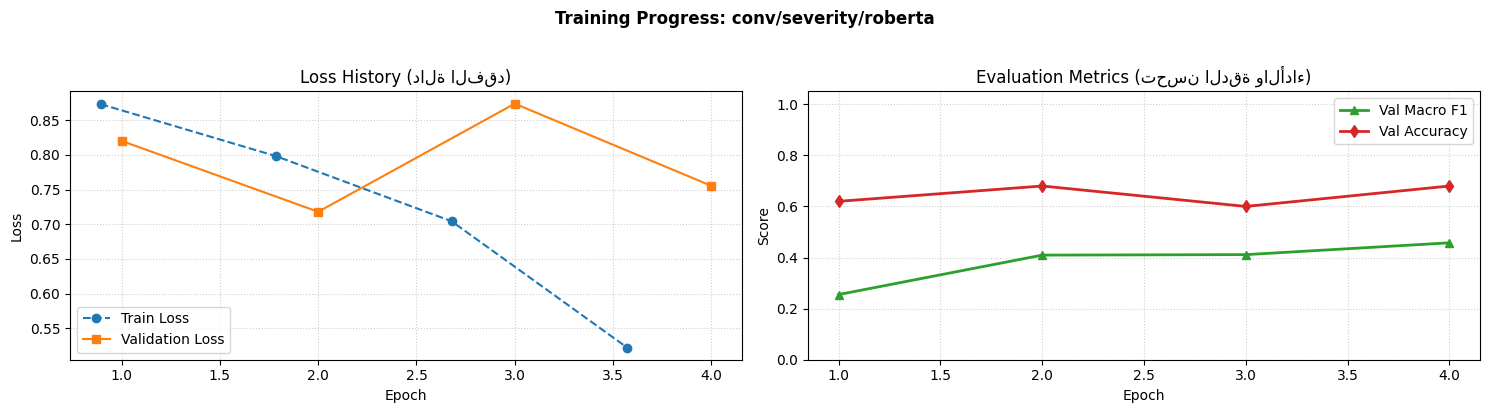

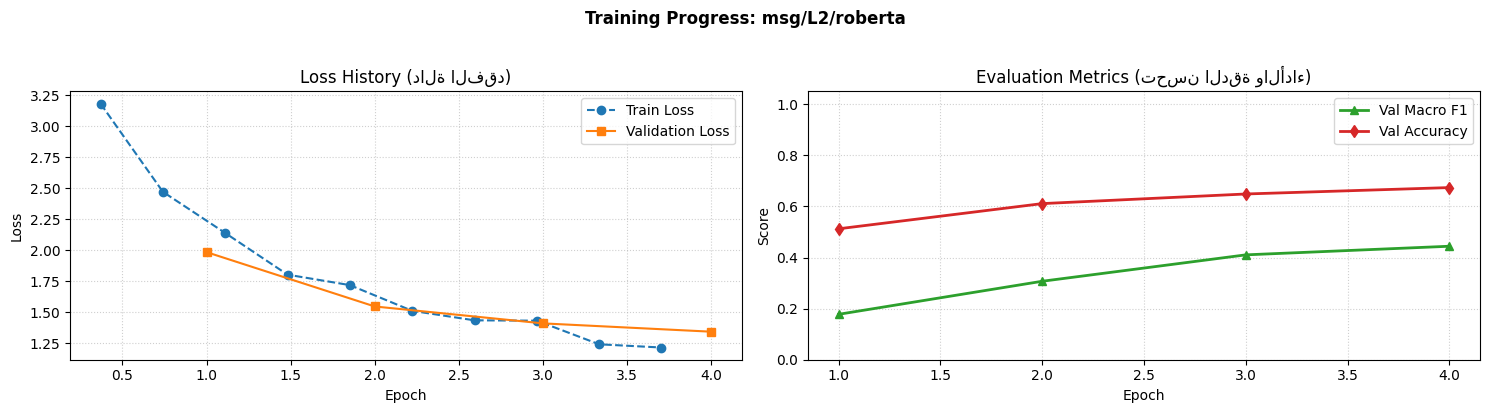

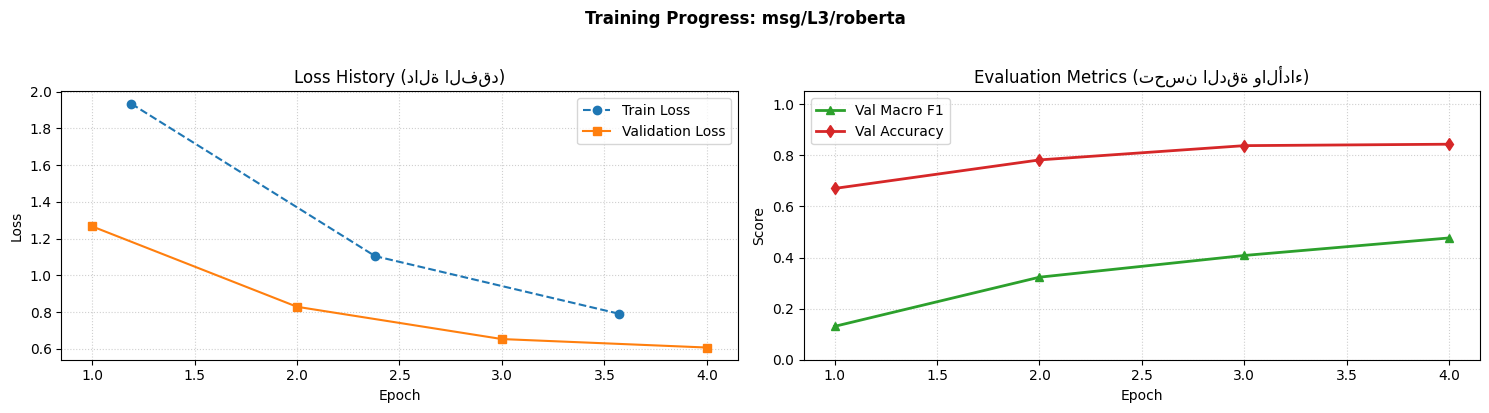

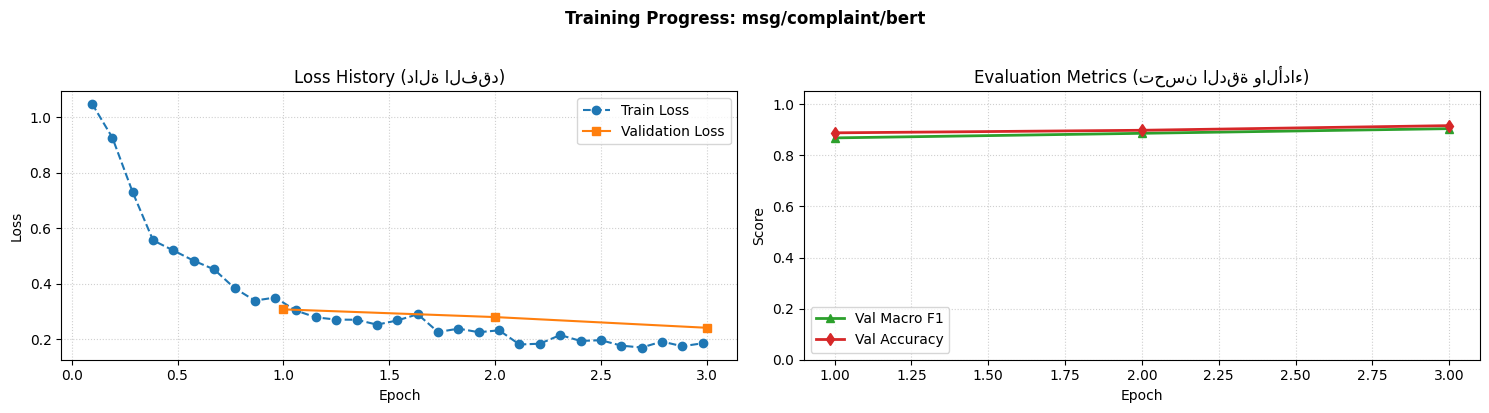

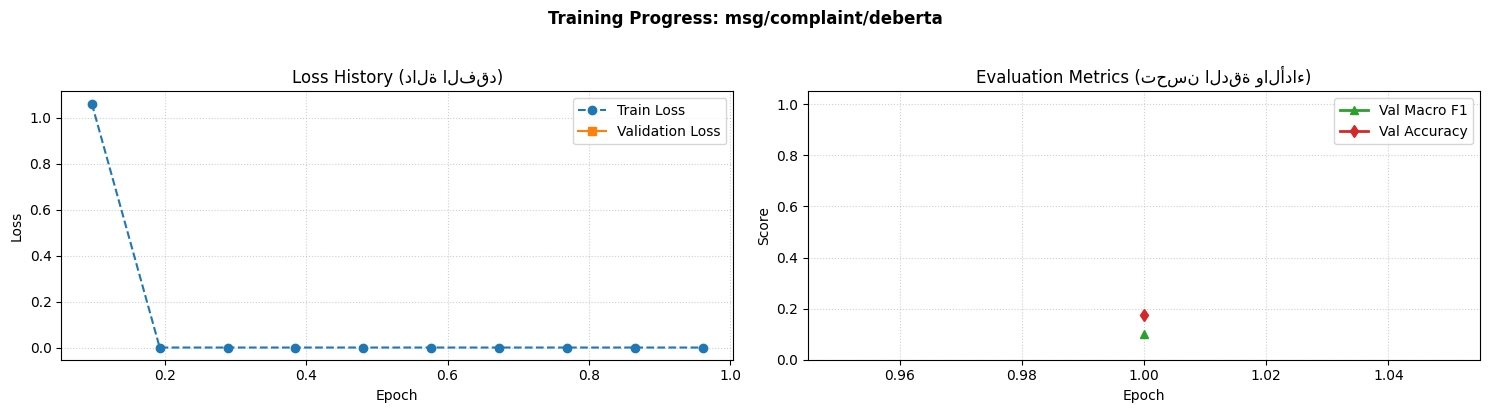

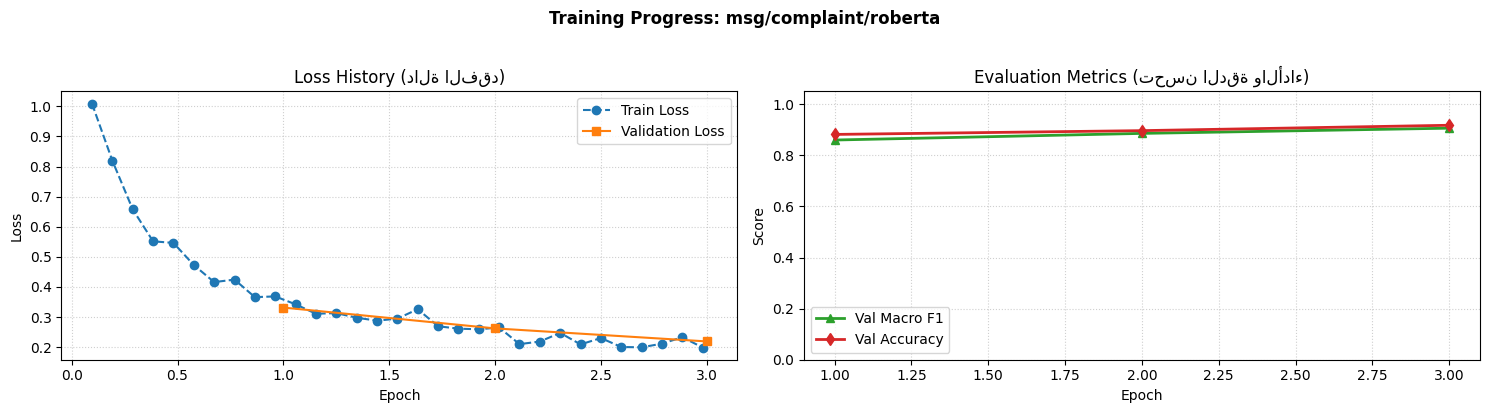

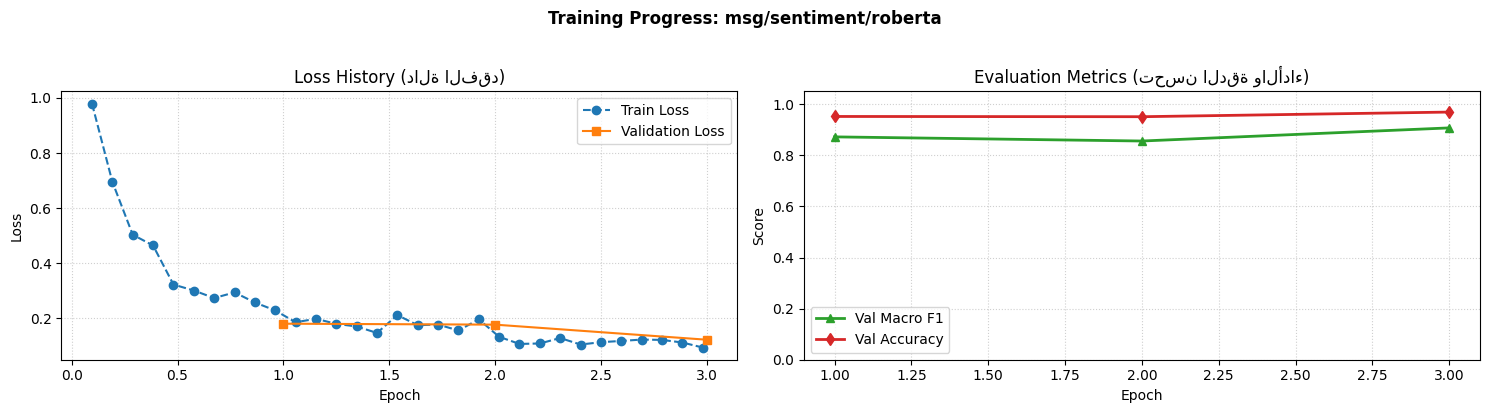

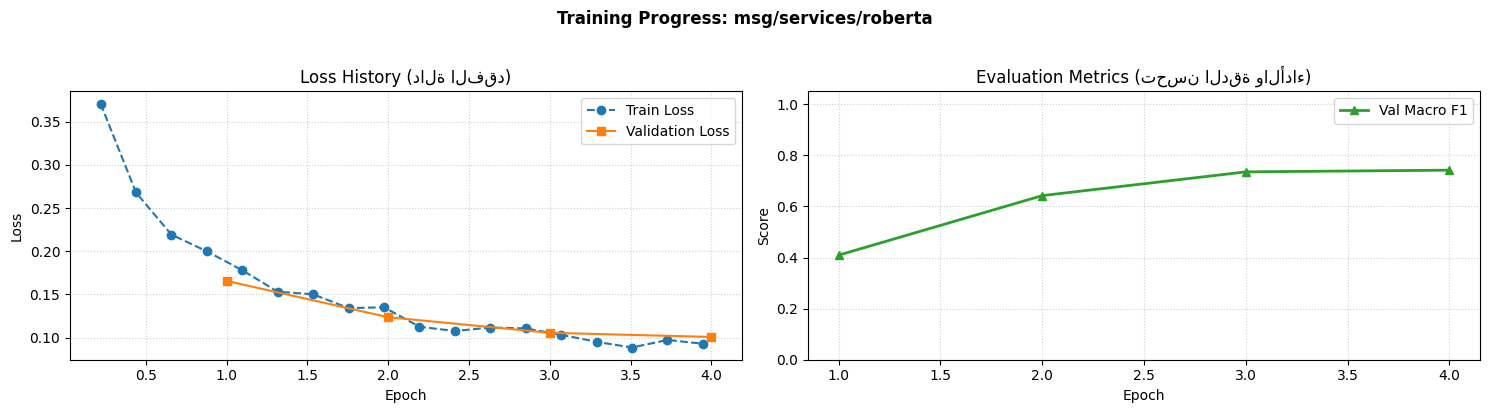

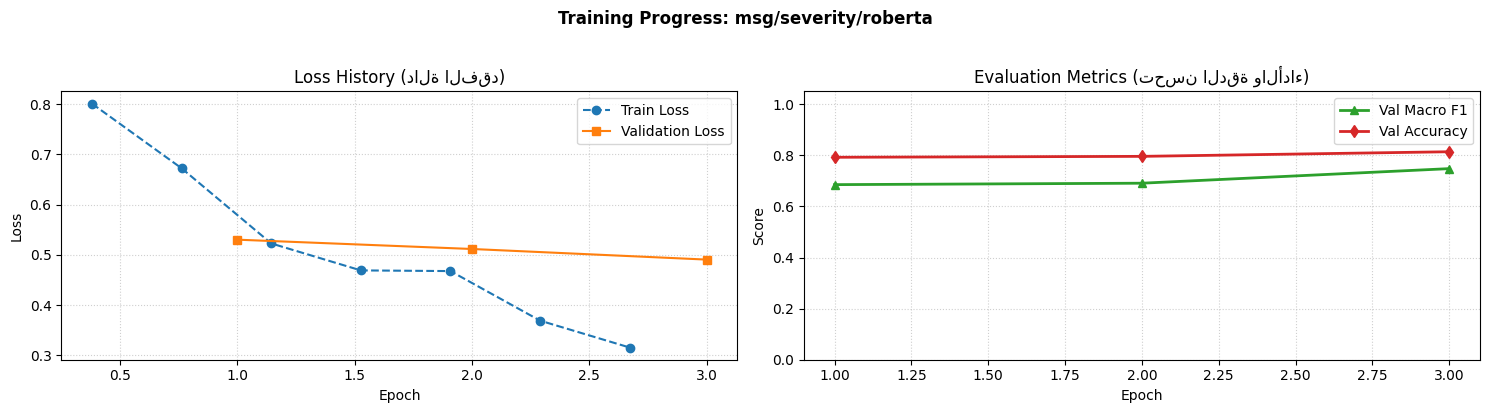

In [14]:
import os
import json
import glob
import matplotlib.pyplot as plt
import pandas as pd

def plot_training_history(ckpt_dir='tcis_outputs/ckpt'):
    """
    دالة تبحث في مجلد الحفظ بشكل عميق عن سجلات تدريب النماذج (trainer_state.json)
    وتقوم برسم منحنيات الفقد (Loss) ومقاييس التحقق (Validation Metrics) لكل نموذج.
    """
    # البحث بشكل تراجعي وعميق عن جميع ملفات حالة المدرب لتفادي مجلدات checkpoint-XXXX الفرعية
    state_files = glob.glob(os.path.join(ckpt_dir, '**/trainer_state.json'), recursive=True)

    if not state_files:
        print("لم يتم العثور على أي سجلات تدريب في المسار المحدد!")
        print("تأكد من إتمام تدريب النماذج وحفظ نقاط الفحص (Checkpoints).")
        return

    print(f"تم العثور على {len(state_files)} من ملفات سجلات التدريب.")

    # استخدام قاموس لتجميع السجلات حسب المهمة لتجنب تكرار الرسم لنفس المهمة
    processed_folders = set()

    for state_file in sorted(state_files):
        # استخراج اسم المهمة والنموذج من المسار
        parts = state_file.split(os.sep)
        # المجلد الرئيسي للمهمة يكون عادة قبل مجلد الـ checkpoint
        folder_name = next((p for p in reversed(parts) if p.startswith('msg_') or p.startswith('conv_')), None)
        if not folder_name:
            folder_name = os.path.basename(os.path.dirname(state_file))

        if folder_name in processed_folders:
            continue
        processed_folders.add(folder_name)

        try:
            with open(state_file, 'r') as f:
                state = json.load(f)

            history = state.get('log_history', [])
            if not history:
                continue

            # فرز السجلات إلى تدريب وتحقق
            train_loss_steps = []
            train_loss_vals = []

            eval_epochs = []
            eval_loss = []
            eval_macro_f1 = []
            eval_accuracy = []

            for log in history:
                epoch = log.get('epoch', None)
                if 'loss' in log and 'eval_loss' not in log:
                    train_loss_steps.append(epoch)
                    train_loss_vals.append(log['loss'])
                elif 'eval_loss' in log:
                    eval_epochs.append(epoch)
                    eval_loss.append(log['eval_loss'])
                    if 'eval_macro_f1' in log:
                        eval_macro_f1.append(log['eval_macro_f1'])
                    if 'eval_accuracy' in log:
                        eval_accuracy.append(log['eval_accuracy'])

            if not train_loss_vals and not eval_loss:
                continue

            # إنشاء الرسم البياني للنموذج الحالي
            fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(15, 4))
            fig.suptitle(f"Training Progress: {folder_name.replace('_', '/')}", fontsize=12, fontweight='bold', y=1.02)

            # الرسمة الأولى: دالة الفقد (Loss Curve)
            if train_loss_vals:
                ax1.plot(train_loss_steps, train_loss_vals, label='Train Loss', color='#1f77b4', marker='o', linestyle='--')
            if eval_loss:
                ax1.plot(eval_epochs, eval_loss, label='Validation Loss', color='#ff7f0e', marker='s')
            ax1.set_title('Loss History (دالة الفقد)')
            ax1.set_xlabel('Epoch')
            ax1.set_ylabel('Loss')
            ax1.grid(True, linestyle=':', alpha=0.6)
            ax1.legend()

            # الرسمة الثانية: مقاييس التحقق والتحسن (Accuracy / F1-Score)
            if eval_macro_f1:
                ax2.plot(eval_epochs, eval_macro_f1, label='Val Macro F1', color='#2ca02c', marker='^', linewidth=2)
            if eval_accuracy:
                ax2.plot(eval_epochs, eval_accuracy, label='Val Accuracy', color='#d62728', marker='d', linewidth=2)
            ax2.set_title('Evaluation Metrics (تحسن الدقة والأداء)')
            ax2.set_xlabel('Epoch')
            ax2.set_ylabel('Score')
            ax2.set_ylim(0, 1.05)
            ax2.grid(True, linestyle=':', alpha=0.6)
            ax2.legend()

            plt.tight_layout()
            plt.show()

        except Exception as e:
            print(f"فشل رسم سجل {state_file}: {e}")

# تشغيل الرسم البياني فوراً
plot_training_history()

## 7) مقارنة نهائية: خطوط الأساس مقابل Transformers

model,bert,deberta,roberta,tfidf+linsvm,tfidf+logreg,tfidf+mnb
task,,,,,,
conv/L2,NaN,NaN,0.121,0.317,0.234,0.064
conv/L3,NaN,NaN,0.125,0.282,0.173,0.069
conv/complaint,NaN,NaN,0.567,0.515,0.524,0.318
conv/sentiment,NaN,NaN,0.790,0.527,0.530,0.236
conv/services,NaN,NaN,0.449,NaN,0.485,0.191
conv/severity,NaN,NaN,0.416,0.428,0.421,0.295
msg/L2,NaN,NaN,0.393,0.494,0.493,0.100
msg/L3,NaN,NaN,0.415,0.775,0.763,0.223
msg/complaint,0.903,0.095,0.897,0.761,0.754,0.568


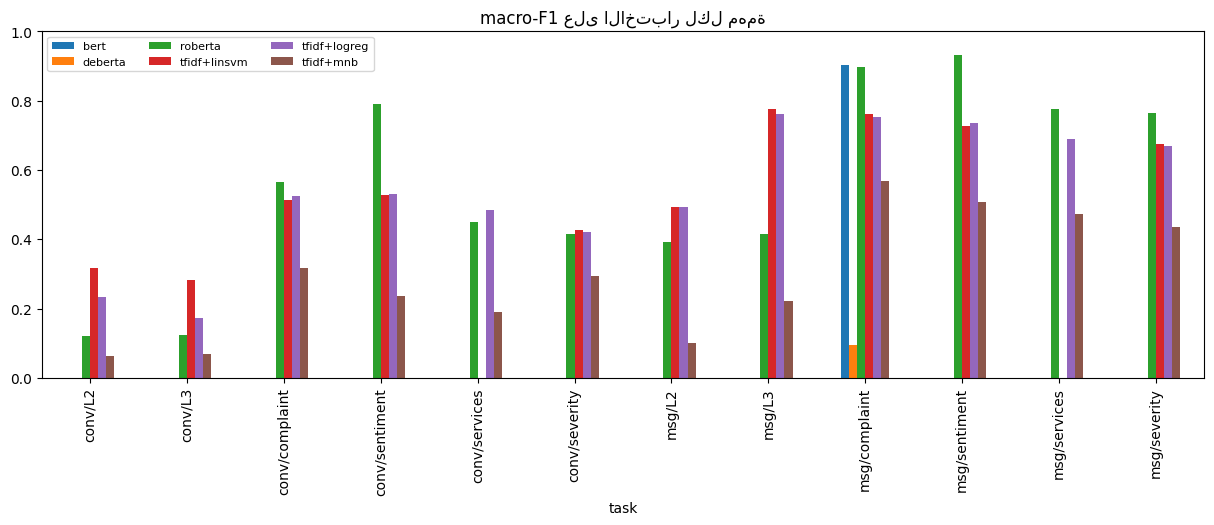

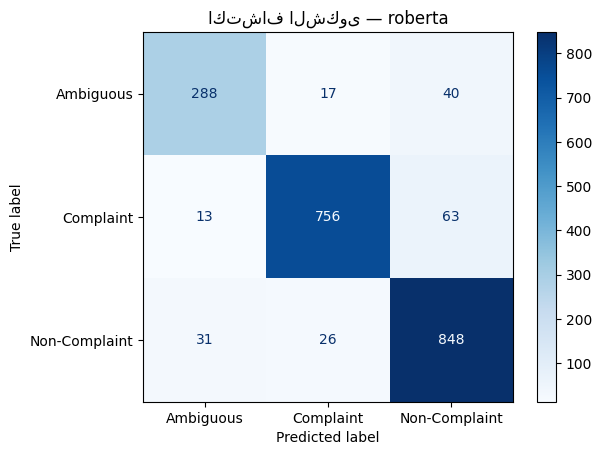

               precision    recall  f1-score   support

    Ambiguous      0.867     0.835     0.851       345
    Complaint      0.946     0.909     0.927       832
Non-Complaint      0.892     0.937     0.914       905

     accuracy                          0.909      2082
    macro avg      0.902     0.893     0.897      2082
 weighted avg      0.909     0.909     0.909      2082



In [15]:
allres = pd.concat([base_df, ft_df.drop(columns=['val_macro_f1'], errors='ignore')], ignore_index=True)
pv = allres.pivot_table(index='task', columns='model', values='macro_f1').round(3); display(pv)
pv.plot.bar(figsize=(15, 4.5), title='macro-F1 على الاختبار لكل مهمة'); plt.ylim(0, 1); plt.legend(ncol=3, fontsize=8); plt.show()
allres.to_csv(f'{OUT_DIR}/model_comparison.csv', index=False)

# مصفوفة الالتباس للنموذج الأفضل في الشكوى
from sklearn.metrics import ConfusionMatrixDisplay
lte, yte = FT_PREDS[('msg/complaint', BEST)]
ConfusionMatrixDisplay.from_predictions(yte, lte.argmax(1), display_labels=TASKS['msg/complaint']['labels'], cmap='Blues'); plt.title(f'اكتشاف الشكوى — {BEST}'); plt.show()
print(classification_report(yte, lte.argmax(1), target_names=TASKS['msg/complaint']['labels'], digits=3))

## 8) اكتشاف الشكاوى على مستويين: رسالة مقابل محادثة
نقارن (أ) نموذجًا مباشرًا على نص المحادثة الكامل بـ (ب) تجميع تنبؤات رسائل العميل الفردية داخل المحادثة.

In [16]:
def pick_path(key):
    c = [(mk, p) for (k, mk), p in FT_PATHS.items() if k == key]
    if not c: return None
    sel = [x for x in c if x[0] == BEST]; return (sel or c)[0][1]

_cache = {}
@torch.no_grad()
def predict_proba(path, texts, bs=64):
    if path not in _cache:
        tok = AutoTokenizer.from_pretrained(path); mdl = AutoModelForSequenceClassification.from_pretrained(path).to(DEVICE).eval()
        _cache[path] = (tok, mdl, json.load(open(f'{path}/tcis_meta.json')))
    tok, mdl, meta = _cache[path]; out = []
    for i in range(0, len(texts), bs):
        enc = tok(list(texts[i:i + bs]), truncation=True, max_length=meta['maxlen'], padding=True, return_tensors='pt').to(DEVICE)
        lg = mdl(**enc).logits.float().cpu().numpy()
        out.append(1 / (1 + np.exp(-lg)) if meta['kind'] == 'multilabel' else np.exp(lg - lg.max(1, keepdims=True)) / np.exp(lg - lg.max(1, keepdims=True)).sum(1, keepdims=True))
    return np.vstack(out), meta

def customer_turns(txt): return [l[len('[CUSTOMER]'):].strip() for l in str(txt).split('\n') if l.startswith('[CUSTOMER]')] or [str(txt)]

p_msg, p_conv = pick_path('msg/complaint'), pick_path('conv/complaint')
if p_msg and p_conv:
    test = CONV[CONV.split == 'test'].reset_index(drop=True)
    P, meta = predict_proba(p_conv, test.text.tolist()); lab = meta['labels']; direct = P.argmax(1)
    ci, ai = lab.index('Complaint'), lab.index('Ambiguous')
    agg = []
    for txt in test.text:
        turns = customer_turns(txt); pm, mmeta = predict_proba(p_msg, turns); ml = mmeta['labels']
        pc, pa = pm[:, ml.index('Complaint')].max(), pm[:, ml.index('Ambiguous')].max()
        agg.append('Complaint' if pc >= .5 else ('Ambiguous' if pa >= .5 else 'Non-Complaint'))
    y = test.complaint_status.values
    print('مباشر على المحادثة  macro-F1:', round(f1_score(y, [lab[i] for i in direct], average='macro'), 4))
    print('تجميع رسائل العميل macro-F1:', round(f1_score(y, agg, average='macro'), 4))

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

مباشر على المحادثة  macro-F1: 0.567
تجميع رسائل العميل macro-F1: 0.6727


## 9) المشاعر: نموذج جاهز مقابل نموذج مُدرَّب على بياناتك
النموذج الجاهز ثلاثي الفئات (لا يعرف `Mixed`)، فنقارن على الفئات الثلاث المشتركة فقط.

In [17]:
from transformers import pipeline
tt = TASKS['msg/sentiment']; te = tt['test'].assign(y_lab=lambda d: d.y.map(dict(enumerate(tt['labels']))))
te3 = te[te.y_lab.isin(['Negative', 'Neutral', 'Positive'])]
pp = pipeline('text-classification', model=SENT_PRETRAINED, device=0 if DEVICE == 'cuda' else -1, truncation=True, max_length=128, batch_size=64)
zs = [r['label'].capitalize() for r in pp(te3.text.tolist())]
print('جاهز (Cardiff)  macro-F1 على 3 فئات:', round(f1_score(te3.y_lab, zs, average='macro'), 4))
sp = pick_path('msg/sentiment')
if sp:
    Ps, ms = predict_proba(sp, te3.text.tolist()); ft = [ms['labels'][i] for i in Ps.argmax(1)]
    ft = [x if x != 'Mixed' else 'Neutral' for x in ft]
    print('مُدرَّب على بياناتك macro-F1 على 3 فئات:', round(f1_score(te3.y_lab, ft, average='macro'), 4))

config.json:   0%|          | 0.00/929 [00:00<?, ?B/s]

pytorch_model.bin: reconstructing file:   0%|          |  0.00B /  501MB            

pytorch_model.bin: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

[transformers] RobertaForSequenceClassification LOAD REPORT from: cardiffnlp/twitter-roberta-base-sentiment-latest
Key                         | Status     |  | 
----------------------------+------------+--+-
roberta.pooler.dense.weight | UNEXPECTED |  | 
roberta.pooler.dense.bias   | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


vocab.json:   0%|          | 0.00/899k [00:00<?, ?B/s]

... (3 outputs left out)

special_tokens_map.json:   0%|          | 0.00/239 [00:00<?, ?B/s]

جاهز (Cardiff)  macro-F1 على 3 فئات: 0.5916


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

مُدرَّب على بياناتك macro-F1 على 3 فئات: 0.9667


## 10) التمثيلات الدلالية: mpnet مقابل MiniLM
المعيار: نقاء الجيران الأقرب (هل أقرب جار يشترك في فئة المشكلة L2؟) وزمن الاستخراج.

In [18]:
import time
from sentence_transformers import SentenceTransformer
from sklearn.neighbors import NearestNeighbors

# عناصر العناقيد: كل شكاوى مستوى الرسالة + نص العميل في محادثات الشكاوى (الأخيرة فقط لها زمن)
CONV_C = CONV[CONV.complaint_status == 'Complaint'].copy(); CONV_C['text'] = CONV_C['customer_text_cleaned'].fillna(CONV_C['text'])
MSG_C  = MSG[MSG.complaint_status == 'Complaint'].copy()
ITEMS = pd.concat([MSG_C[['text', 'l1_set', 'l2', 'src']].assign(conversation_id=None, t=pd.NaT),
                   CONV_C[['text', 'l1_set', 'l2', 'src', 'conversation_id', 't', 'company_text_cleaned']]], ignore_index=True)
ITEMS = ITEMS[ITEMS.text.str.len() > 10].drop_duplicates('text').reset_index(drop=True)
print('عناصر التجميع:', len(ITEMS), '| منها بزمن:', ITEMS.t.notna().sum())

def nn_purity(E, labels, k=5):
    ok = labels.notna().values; E, y = E[ok], labels[ok].values
    idx = NearestNeighbors(n_neighbors=k + 1, metric='cosine').fit(E).kneighbors(E, return_distance=False)[:, 1:]
    return float(np.mean([collections.Counter(y[r]).most_common(1)[0][0] == y[i] for i, r in enumerate(idx)]))

EMB, emb_rows = {}, []
for k, name in EMB_MODELS.items():
    st = SentenceTransformer(name, device=DEVICE); t0 = time.time()
    EMB[k] = st.encode(ITEMS.text.tolist(), batch_size=128, normalize_embeddings=True, show_progress_bar=False)
    emb_rows.append(dict(model=k, seconds=round(time.time() - t0, 1), dim=EMB[k].shape[1], nn_purity_L2=round(nn_purity(EMB[k], ITEMS.l2), 4)))
    del st
display(pd.DataFrame(emb_rows))
BEST_EMB = max(emb_rows, key=lambda r: r['nn_purity_L2'])['model']; E = EMB[BEST_EMB]; print('التمثيل المختار:', BEST_EMB)

عناصر التجميع: 9154 | منها بزمن: 1404


modules.json:   0%|          | 0.00/349 [00:00<?, ?B/s]

config_sentence_transformers.json:   0%|          | 0.00/116 [00:00<?, ?B/s]

README.md:   0%|          | 0.00/11.6k [00:00<?, ?B/s]

sentence_bert_config.json:   0%|          | 0.00/53.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/571 [00:00<?, ?B/s]

... (19 outputs left out)

special_tokens_map.json:   0%|          | 0.00/112 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/190 [00:00<?, ?B/s]

,model,seconds,dim,nn_purity_L2
0,mpnet,29.6,768,0.5057
1,minilm,5.3,384,0.5385


التمثيل المختار: minilm


## 11) تجميع الشكاوى المتشابهة: UMAP + HDBSCAN + BERTopic
يُقاس التجميع بمقارنته بـ L2 (homogeneity/NMI)، مع الإبقاء على فئة الضجيج (-1) كما هي دون إجبار.

In [19]:
import umap, hdbscan
from sklearn.metrics import homogeneity_score, normalized_mutual_info_score
from sklearn.feature_extraction.text import CountVectorizer
from bertopic import BERTopic

def mk_umap():  return umap.UMAP(n_neighbors=15, n_components=5, min_dist=0.0, metric='cosine', random_state=SEED)
def mk_hdb():   return hdbscan.HDBSCAN(min_cluster_size=8, min_samples=3, metric='euclidean', cluster_selection_method='eom', prediction_data=True)

topic_model = BERTopic(embedding_model=None, umap_model=mk_umap(), hdbscan_model=mk_hdb(),
                       vectorizer_model=CountVectorizer(stop_words='english', ngram_range=(1, 2), min_df=2), top_n_words=8, calculate_probabilities=False, verbose=False)
ITEMS['cluster'], _ = topic_model.fit_transform(ITEMS.text.tolist(), embeddings=E)
ok = (ITEMS.cluster >= 0) & ITEMS.l2.notna()
print('عدد العناقيد:', ITEMS.cluster.nunique() - (-1 in set(ITEMS.cluster)), '| نسبة الضجيج:', round((ITEMS.cluster < 0).mean(), 3))
print('homogeneity vs L2:', round(homogeneity_score(ITEMS.l2[ok], ITEMS.cluster[ok]), 3), '| NMI:', round(normalized_mutual_info_score(ITEMS.l2[ok], ITEMS.cluster[ok]), 3))
info = topic_model.get_topic_info(); display(info[info.Topic >= 0].head(20)[['Topic', 'Count', 'Name']])

عدد العناقيد: 228 | نسبة الضجيج: 0.348
homogeneity vs L2: 0.597 | NMI: 0.473


,Topic,Count,Name
1,0,222,0_4g_3g_speed_2g
2,1,158,1_internet internet_internet_help internet_int...
3,2,143,2_mobilecarexi_mobilecare_mobilecarexi interne...
4,3,104,3_iphone_deal_upgrade_trade
5,4,99,4_issue_issue company_resolved_issue resolved
6,5,97,5_overcharged_lower_fees_hidden
7,6,94,6_customer service_worst customer_customer_use...
8,7,84,7_user worst_worst internet_worst_worst network
9,8,82,8_airtime_borrow_transfer airtime_check airtime
10,9,79,9_unlimited data_unlimited_data_data unlimited


### 11.1) Cross-Encoder للتحقق من الأزواج
نقارن متوسط تشابه أزواج داخل نفس العنقود بأزواج عشوائية، ونُعلّم الأعضاء الضعيفة بالنسبة لنص مركز العنقود.

In [20]:
from sentence_transformers import CrossEncoder
ce = CrossEncoder(CROSS_ENCODER, device=DEVICE)
rng = np.random.default_rng(SEED); in_pairs, rnd_pairs = [], []
for c, g in ITEMS[ITEMS.cluster >= 0].groupby('cluster'):
    if len(g) >= 2:
        for _ in range(min(5, len(g))):
            a, b = rng.choice(g.index, 2, replace=False); in_pairs.append((ITEMS.text[a], ITEMS.text[b]))
for _ in range(len(in_pairs)):
    a, b = rng.choice(len(ITEMS), 2, replace=False); rnd_pairs.append((ITEMS.text[a], ITEMS.text[b]))
si, sr = ce.predict(in_pairs, show_progress_bar=False), ce.predict(rnd_pairs, show_progress_bar=False)
print(f'تشابه داخل العنقود {np.mean(si):.3f}  مقابل عشوائي {np.mean(sr):.3f}')

ITEMS['ce_score'] = np.nan
for c, g in ITEMS[ITEMS.cluster >= 0].groupby('cluster'):
    cen = E[g.index].mean(0); medoid = g.index[np.argmax(E[g.index] @ cen)]
    ITEMS.loc[g.index, 'ce_score'] = ce.predict([(ITEMS.text[medoid], ITEMS.text[i]) for i in g.index], show_progress_bar=False)
ITEMS['verified'] = (ITEMS.ce_score >= 0.4) & (ITEMS.cluster >= 0)
print('نسبة الأعضاء الموثّقة:', round(ITEMS.verified.sum() / max((ITEMS.cluster >= 0).sum(), 1), 3))

config.json:   0%|          | 0.00/608 [00:00<?, ?B/s]

model.safetensors: reconstructing file:   0%|          |  0.00B /  499MB            

model.safetensors: downloading bytes:           |  0.00B            

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

tokenizer_config.json:   0%|          | 0.00/1.33k [00:00<?, ?B/s]

vocab.json:   0%|          | 0.00/798k [00:00<?, ?B/s]

merges.txt:   0%|          | 0.00/456k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/3.56M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/1.01k [00:00<?, ?B/s]

تشابه داخل العنقود 0.400  مقابل عشوائي 0.233
نسبة الأعضاء الموثّقة: 0.642


## 12) الشكاوى الجماعية ومؤشرات الأعطال
**المنهج:** لكل عنقود له أعضاء مؤرّخة نمرّر نافذة 24 ساعة ونحسب احتمال رؤية هذا العدد بالصدفة بتوزيع بواسون بمعدل العنقود الأساسي. نضيف فحصًا لتفجر حجم الخدمة يوميًا.

**مستويات الثقة (الأعطال لا تُؤكَّد من نصوص العملاء وحدها):**
- تُصحَّح القيمة p بعدد النوافذ الزمنية ثم بـ Benjamini–Hochberg عبر العناقيد (q) لتفادي الإنذارات الكاذبة من كثرة الاختبارات.
- `مرشح للمراقبة`: q<0.05 وعدد≥4.
- `مؤشر محتمل`: q<0.01 وعدد≥5.
- `مؤشر مدعوم برد الشركة`: كما سبق + ≥30% من المحادثات فيها رد شركة يقرّ بمشكلة. ما زال **غير مؤكد رسميًا**.
- `عطل مؤكد`: يتطلب مصدرًا خارجيًا (نظام مراقبة الشبكة/بيان رسمي) فلا يصدر هنا.

In [21]:
from scipy.stats import poisson
ACK = re.compile(r"(outage|known issue|aware of|we'?re aware|looking into (it|this|the)|investigating|experiencing (an? )?(issue|problem)|working (on|to)|engineers?|service (is )?(down|restored)|apolog)", re.I)
OUTAGE_WORDS = re.compile(r"(down|outage|no (service|signal|internet|connection)|not working|can'?t connect|offline|dropping|disconnect)", re.I)
T = ITEMS[ITEMS.t.notna() & (ITEMS.cluster >= 0)].copy(); T['t'] = pd.to_datetime(T.t, utc=True)
t_lo, t_hi = max(T.t.min(), pd.Timestamp('2017-10-01', tz='UTC')), T.t.max(); span_h = max((t_hi - t_lo).total_seconds() / 3600, 24)
W = 24; alerts = []
for c, g in T.groupby('cluster'):
    if len(g) < 6: continue
    ts = np.sort(g.t.values.astype('datetime64[s]').astype(np.int64)) / 3600.0
    lam = len(ts) * W / span_h; best = (1.0, 0, 0)
    for i in range(len(ts)):
        k = int(np.sum((ts >= ts[i]) & (ts <= ts[i] + W))); p = poisson.sf(k - 1, lam)
        if p < best[0]: best = (p, k, ts[i])
    p, k, t0 = best
    ack = g.company_text_cleaned.fillna('').map(lambda s: bool(ACK.search(s))).mean()
    sym = g.text.map(lambda s: bool(OUTAGE_WORDS.search(s))).mean()
    svc = collections.Counter(s for l in g.l1_set for s in l).most_common(2)
    alerts.append(dict(cluster=c, topic=info.set_index('Topic').Name.get(c, ''), window_start=pd.to_datetime(t0 * 3600, unit='s', utc=True), count_24h=k, members=len(g),
                       p_scan=min(1.0, p * span_h / W), services=[s for s, _ in svc], company_ack=round(ack, 2), outage_terms=round(sym, 2)))

ALERTS = pd.DataFrame(alerts)
if len(ALERTS):
    # تصحيح التعدد: p×عدد النوافذ (مسح زمني) ثم Benjamini–Hochberg عبر العناقيد
    o = ALERTS.p_scan.rank(method='first').astype(int); m_ = len(ALERTS)
    q = (ALERTS.p_scan * m_ / o); ALERTS['q_value'] = q[ALERTS.p_scan.sort_values(ascending=False).index].cummin()[ALERTS.index].clip(upper=1)
    def lvl(r):
        if r.q_value < 0.01 and r.count_24h >= 5: return 'مؤشر مدعوم برد الشركة' if r.company_ack >= 0.3 else 'مؤشر محتمل'
        if r.q_value < 0.05 and r.count_24h >= 4: return 'مرشح للمراقبة'
        return None
    ALERTS['level'] = ALERTS.apply(lvl, axis=1); ALERTS = ALERTS.dropna(subset=['level']).sort_values('q_value')
else:
    ALERTS = pd.DataFrame(columns=['cluster', 'level', 'p_scan', 'q_value'])
display(ALERTS.head(15))

# تفجر حجم الخدمة يوميًا مقابل متوسط 7 أيام سابقة
sv = T.explode('l1_set').dropna(subset=['l1_set']); sv['day'] = sv.t.dt.floor('D')
dly = sv.groupby(['day', 'l1_set']).size().unstack(fill_value=0).asfreq('D', fill_value=0)
base = dly.shift(1).rolling(7, min_periods=3).mean(); z = (dly - base) / np.sqrt(base + 1)
spikes = z.stack().rename('z').reset_index(); spikes = spikes[spikes.z >= 3].merge(dly.stack().rename('count').reset_index())
display(spikes.sort_values('z', ascending=False).head(10))
ALERTS.to_csv(f'{OUT_DIR}/collective_alerts.csv', index=False); ITEMS.to_csv(f'{OUT_DIR}/clustered_items.csv', index=False)

,cluster,topic,window_start,count_24h,members,p_scan,services,company_ack,outage_terms,q_value,level
2,3,3_iphone_deal_upgrade_trade,2017-10-26 15:48:27+00:00,7,35,0.000116,"[subscription_plans, billing_payments]",0.11,0.26,0.004881,مؤشر محتمل
36,101,101_company tuesday_tuesday_website_company tu...,2017-11-07 16:02:11+00:00,4,8,0.000592,"[technical_support, customer_support]",0.25,0.75,0.012423,مرشح للمراقبة


,day,l1_set,z,count
6,2017-11-21 00:00:00+00:00,subscription_plans,4.684320,8
2,2017-10-27 00:00:00+00:00,subscription_plans,3.535534,6
5,2017-11-21 00:00:00+00:00,mobile_data,3.532778,5
4,2017-11-14 00:00:00+00:00,billing_payments,3.318060,6
1,2017-10-27 00:00:00+00:00,billing_payments,3.273268,5
3,2017-11-06 00:00:00+00:00,number_sim,3.040026,5
0,2017-10-04 00:00:00+00:00,mobile_network,3.000000,3


## 13) FLAN-T5: ملخص منظم لكل مؤشر
يُستخدم لتوليد مخرجات منظمة قابلة للقراءة (الخدمة، العرض، النطاق الزمني، درجة الثقة) وليس لإصدار حكم تصنيفي.

In [22]:
from transformers import AutoModelForSeq2SeqLM
s2s_tok = AutoTokenizer.from_pretrained(SEQ2SEQ); s2s = AutoModelForSeq2SeqLM.from_pretrained(SEQ2SEQ).to(DEVICE).eval()

@torch.no_grad()
def summarize_incident(texts, services, level):
    ex = ' | '.join(t[:160] for t in texts[:6])
    prompt = (f"Customer complaints from a telecom company: {ex}\nAnswer in one line using the format "
              f"'Affected service: <service>; Main symptom: <symptom>; Likely cause: <cause or unknown>'. Services hint: {', '.join(services)}.")
    enc = s2s_tok(prompt, return_tensors='pt', truncation=True, max_length=512).to(DEVICE)
    out = s2s.generate(**enc, max_new_tokens=64, num_beams=4)
    return s2s_tok.decode(out[0], skip_special_tokens=True)

if len(ALERTS):
    for _, a in ALERTS.head(5).iterrows():
        mem = T[T.cluster == a.cluster].text.tolist()
        print(f"[{a.level}] cluster {a.cluster} — {a.count_24h} شكوى/24س — q={a.q_value:.1e}\n   {summarize_incident(mem, a.services, a.level)}\n   (غير مؤكد رسميًا)\n")

config.json:   0%|          | 0.00/1.40k [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/2.54k [00:00<?, ?B/s]

spiece.model: reconstructing file:   0%|          |  0.00B /  792kB            

spiece.model: downloading bytes:           |  0.00B            

tokenizer.json:   0%|          | 0.00/2.42M [00:00<?, ?B/s]

special_tokens_map.json:   0%|          | 0.00/2.20k [00:00<?, ?B/s]

... (2 outputs left out)

Loading weights:   0%|          | 0/282 [00:00<?, ?it/s]

[transformers] The tied weights mapping and config for this model specifies to tie shared.weight to lm_head.weight, but both are present in the checkpoints with different values, so we will NOT tie them. You should update the config with `tie_word_embeddings=False` to silence this warning.


generation_config.json:   0%|          | 0.00/147 [00:00<?, ?B/s]

[مؤشر محتمل] cluster 3 — 7 شكوى/24س — q=4.9e-03
   'Affected service: service>; Main symptom: symptom>; Likely cause: cause or unknown>'. Services hint: subscription_plans, billing_payments.
   (غير مؤكد رسميًا)

[مرشح للمراقبة] cluster 101 — 4 شكوى/24س — q=1.2e-02
   Affected service: service>; Main symptom: symptom>; Likely cause: cause or unknown>
   (غير مؤكد رسميًا)



## 14) الربط الهرمي والاتساق L1 ← L2 ← L3
نبني الشجرة من البيانات ثم نفرض الاتساق عند الاستدلال بحجب الأبناء غير التابعين للأب المتوقع.

In [23]:
tax_l2, tax_l3 = collections.defaultdict(set), collections.defaultdict(set)
for df in (comp, conv, msgs):
    for s in df.classifications:
        for d in parse_cls(s):
            if d['l1'] and d['l2'] and d['l1'] not in NONSERVICE and d['l2'] not in NONISSUE:
                tax_l2[d['l1']].add(d['l2'])
                if d['l3']: tax_l3[d['l2']].add(d['l3'])

def hierarchical_decode(p1, p2, p3, meta1, meta2, meta3, k_services=2):
    """p1: احتمالات الخدمات (متعدد)، p2/p3: softmax. يرجع (خدمات، L2 متسق، L3 متسق)."""
    svc = [meta1['labels'][j] for j in np.argsort(-p1)[:k_services] if p1[j] >= meta1['thr'][j]] or [meta1['labels'][int(np.argmax(p1))]]
    allowed2 = set().union(*[tax_l2[s] for s in svc]); l2 = meta2['labels']
    m2 = np.array([(x in allowed2) or x == 'other_rare' for x in l2]); i2 = int(np.argmax(np.where(m2, p2, -1))); l2p = l2[i2]
    l3 = meta3['labels']; m3 = np.array([(x in tax_l3[l2p]) or x == 'other_rare' for x in l3]); i3 = int(np.argmax(np.where(m3, p3, -1)))
    return svc, l2p, l3[i3]

# قياس الاتساق قبل/بعد على الاختبار
pS, p2_, p3_ = pick_path('msg/services'), pick_path('msg/L2'), pick_path('msg/L3')
if pS and p2_ and p3_:
    tst = MSG[(MSG.split == 'test') & (MSG.complaint_status == 'Complaint')].text.tolist()[:400]
    P1, m1 = predict_proba(pS, tst); P2, m2 = predict_proba(p2_, tst); P3, m3 = predict_proba(p3_, tst)
    raw_ok = hier_ok = 0
    for a, b, c3 in zip(P1, P2, P3):
        l2r = m2['labels'][int(b.argmax())]; l3r = m3['labels'][int(c3.argmax())]
        svc_r = [m1['labels'][int(a.argmax())]]
        raw_ok += (l2r in tax_l2[svc_r[0]] or l2r == 'other_rare') and (l3r in tax_l3[l2r] or 'other_rare' in (l2r, l3r))
        s, l2h, l3h = hierarchical_decode(a, b, c3, m1, m2, m3); hier_ok += (l3h in tax_l3[l2h] or 'other_rare' in (l2h, l3h))
    print(f'اتساق التسلسل قبل الحجب: {raw_ok / len(tst):.3f} | بعد الحجب: {hier_ok / len(tst):.3f}')

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

اتساق التسلسل قبل الحجب: 0.740 | بعد الحجب: 1.000


## 15) خط الإنتاج المتكامل: محادثة جديدة ← تحليل كامل
يُنتج: الشكوى، الخدمات، L2/L3 متسقة، المشاعر، الخطورة، أقرب عنقود شكاوى قائم وحالته.

In [24]:
EMB_ST = SentenceTransformer(EMB_MODELS[BEST_EMB], device=DEVICE)
CL_IDX = np.where(ITEMS.cluster.values >= 0)[0]; CL_NN = NearestNeighbors(n_neighbors=5, metric='cosine').fit(E[CL_IDX])
ALERT_BY_CLUSTER = {int(a.cluster): a for _, a in ALERTS.iterrows()} if len(ALERTS) else {}

def analyze(conversation_text, level='conv'):
    """conversation_text: نص بالأدوار [CUSTOMER]/[COMPANY] أو رسالة واحدة."""
    lv = level; res = {}
    def top(key, txt):
        p = pick_path(key)
        if not p: return None
        P, meta = predict_proba(p, [txt]); return P[0], meta
    r = top(f'{lv}/complaint', conversation_text)
    if r: res['complaint'] = {r[1]['labels'][int(r[0].argmax())]: round(float(r[0].max()), 3)}
    for t in ('sentiment', 'severity'):
        r = top(f'{lv}/{t}', conversation_text)
        if r: res[t] = {r[1]['labels'][int(r[0].argmax())]: round(float(r[0].max()), 3)}
    cust = ' '.join(customer_turns(conversation_text)); a = top('msg/services', cust); b = top('msg/L2', cust); c = top('msg/L3', cust)
    if a and b and c:
        svc, l2, l3 = hierarchical_decode(a[0], b[0], c[0], a[1], b[1], c[1]); res['services_L1'], res['L2'], res['L3'] = svc, l2, l3
    e = EMB_ST.encode([cust], normalize_embeddings=True); d, ix = CL_NN.kneighbors(e)
    votes = collections.Counter(int(ITEMS.cluster.values[CL_IDX[j]]) for j, dd in zip(ix[0], d[0]) if 1 - dd >= 0.55)
    if votes:
        cl = votes.most_common(1)[0][0]; res['nearest_cluster'] = dict(id=cl, topic=info.set_index('Topic').Name.get(cl, ''), votes=votes[cl],
                                                                        incident_status=(ALERT_BY_CLUSTER[cl].level if cl in ALERT_BY_CLUSTER else 'لا مؤشر'))
    else: res['nearest_cluster'] = None
    return res

demo = ("[CUSTOMER] @user my internet has been down since this morning and the router keeps blinking red. Third time this week!\n"
        "[COMPANY] @user Sorry to hear that. Can you DM us your address?")
print(json.dumps(analyze(demo), ensure_ascii=False, indent=2))

Loading weights:   0%|          | 0/103 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

{
  "complaint": {
    "Complaint": 0.743
  },
  "sentiment": {
    "Negative": 0.986
  },
  "severity": {
    "Medium": 0.899
  },
  "services_L1": [
    "internet_service"
  ],
  "L2": "internet_connection_problems",
  "L3": "internet_service.internet_connection_problems.no_internet_connection",
  "nearest_cluster": {
    "id": 135,
    "topic": "135_light_blinking_red_green",
    "votes": 1,
    "incident_status": "لا مؤشر"
  }
}


## 16) مراجعة بشرية: عينة للتحقق من جودة التسميات الآلية
بما أن التسميات آلية، هذه العينة (الأقل ثقة والأكثر تأثيرًا) تُصدَّر لمراجع بشري ثم تُستخدم لإعادة التقييم.

In [25]:
rev = pd.concat([comp.assign(level='complaint'), conv.assign(level='conversation')], ignore_index=True)
cols = ['level', 'complaint_status', 'complaint_confidence', 'sentiment', 'severity', 'l1_set', 'l2', 'l3', 'confidence_tier']
sample = (rev.sort_values(['review_priority', 'confidence']).groupby('level').head(150))
sample[cols + [c for c in ['cleaned_text', 'conversation_text_with_roles'] if c in sample.columns]].to_csv(f'{OUT_DIR}/human_review_sample.csv', index=False)
print('تم تصدير عينة المراجعة:', f'{OUT_DIR}/human_review_sample.csv')

تم تصدير عينة المراجعة: tcis_outputs/human_review_sample.csv


## 17) حفظ المخرجات
يُحفظ كل شيء داخل `tcis_outputs/`: مقارنة النماذج، العناقيد، التنبيهات، النماذج المُدرَّبة. انسخ المجلد إلى Drive للاحتفاظ به.

In [26]:
try:
    import shutil
    from google.colab import drive
    if os.path.exists('/content/drive/MyDrive'):
        shutil.copytree(OUT_DIR, '/content/drive/MyDrive/tcis_outputs', dirs_exist_ok=True); print('نُسخ إلى Drive')
except ImportError:
    pass
print(os.listdir(OUT_DIR))

['model_comparison.csv', 'human_review_sample.csv', 'models', 'clustered_items.csv', 'ckpt', 'collective_alerts.csv']


In [27]:
import os
import json

models_dir = 'tcis_outputs/models'
print("=== قائمة النماذج المدربة ومكوناتها في المجلد ===\n")

if os.path.exists(models_dir):
    for model_folder in sorted(os.listdir(models_dir)):
        folder_path = os.path.join(models_dir, model_folder)
        if os.path.isdir(folder_path):
            print(f"📁 المجلد: {model_folder}")
            # قراءة ملف الإعدادات الخاص بالنظام المدمج لمعرفة الفئات المخصصة
            meta_path = os.path.join(folder_path, 'tcis_meta.json')
            if os.path.exists(meta_path):
                with open(meta_path, 'r') as f:
                    meta = json.load(f)
                print(f"   - نوع المهمة (Kind): {meta.get('kind')}")
                print(f"   - الفئات المصنفة (Labels): {meta.get('labels')}")

            # عرض الملفات الأساسية للنموذج للتحقق من سلامة البنية
            files = os.listdir(folder_path)
            print(f"   - الملفات الداخلية: {files}\n")
else:
    print(f"المسار {models_dir} غير موجود! تأكد من إتمام التدريب أولاً.")

=== قائمة النماذج المدربة ومكوناتها في المجلد ===

📁 المجلد: conv_L2_roberta
   - نوع المهمة (Kind): single
   - الفئات المصنفة (Labels): ['billing_balance', 'billing_incorrect', 'billing_payment_failure', 'billing_refund', 'device_failure', 'internet_connection_problems', 'internet_speed_problems', 'mobile_coverage_problems', 'mobile_data_connectivity', 'mobile_network_outage', 'other_rare', 'plan_activation', 'support_channel', 'support_delayed', 'support_poor', 'support_unhelpful', 'support_unresolved', 'tech_unresolved', 'tv_channels', 'tv_outage', 'tv_streaming', 'voice_call_drops']
   - الملفات الداخلية: ['training_args.bin', 'tokenizer_config.json', 'model.safetensors', 'config.json', 'tokenizer.json', 'tcis_meta.json']

📁 المجلد: conv_L3_roberta
   - نوع المهمة (Kind): single
   - الفئات المصنفة (Labels): ['billing_payments.billing_balance.credit_balance_dispute', 'customer_support.support_channel.transfer_hold_problem', 'customer_support.support_delayed.long_wait_time', 'custo

### 🛠️ كود إضافي لتنظيف الـ Checkpoints وتقليص حجم النماذج النهائية إلى FP16

الخلية التالية ستقوم بـ:
1. حذف مجلد الـ `ckpt` المؤقت الذي يستهلك المساحة الأكبر بسبب ملفات الـ Optimizer.
2. تحويل أوزان النماذج النهائية في مجلد `models` إلى دقة نصف عائمة (`FP16`) لتقليص حجمها إلى النصف مباشرة.

In [28]:
import os
import shutil
import torch
from transformers import AutoModelForSequenceClassification

# 1. حذف مجلد الـ checkpoint المؤقت لتوفير مساحة ضخمة
ckpt_dir = 'tcis_outputs/ckpt'
if os.path.exists(ckpt_dir):
    print(f"🧹 جاري حذف مجلد نقاط الفحص المؤقتة لإخلاء المساحة: {ckpt_dir}")
    shutil.rmtree(ckpt_dir)
    print("✅ تم حذف مجلد ckpt بنجاح!")

# 2. تحويل النماذج النهائية إلى FP16 لتقليص حجم الملفات إلى النصف (من ~440MB إلى ~220MB للنموذج)
models_dir = 'tcis_outputs/models'
if os.path.exists(models_dir):
    print("\n⚡ جاري تقليص حجم النماذج النهائية عن طريق تحويلها إلى FP16...")
    for model_folder in sorted(os.listdir(models_dir)):
        folder_path = os.path.join(models_dir, model_folder)
        if os.path.isdir(folder_path):
            try:
                # تحميل النموذج
                model = AutoModelForSequenceClassification.from_pretrained(folder_path)
                # تحويل الأوزان إلى نصف دقة FP16
                model = model.half()
                # إعادة حفظ النموذج بنفس المسار للحفاظ على الهيكلية
                model.save_pretrained(folder_path)
                print(f"   🔹 تم تقليص حجم نموذج {model_folder} بنجاح إلى FP16.")
            except Exception as e:
                print(f"   ❌ تعذر تحويل {model_folder}: {e}")

# 3. إعادة ضغط المجلد بعد تقليص حجمه بشكل كبير
output_zip = 'tcis_models_archive_optimized'
print(f"\n📦 جاري إعادة ضغط المجلد المحسن...")
shutil.make_archive(output_zip, 'zip', models_dir)
print(f"🎉 تم حفظ الأرشيف المضغوط المحسن والجديد في: {output_zip}.zip")

🧹 جاري حذف مجلد نقاط الفحص المؤقتة لإخلاء المساحة: tcis_outputs/ckpt
✅ تم حذف مجلد ckpt بنجاح!

⚡ جاري تقليص حجم النماذج النهائية عن طريق تحويلها إلى FP16...


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   🔹 تم تقليص حجم نموذج conv_L2_roberta بنجاح إلى FP16.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

... (33 outputs left out)

   🔹 تم تقليص حجم نموذج msg_services_roberta بنجاح إلى FP16.


Loading weights:   0%|          | 0/201 [00:00<?, ?it/s]

Writing model shards:   0%|          | 0/1 [00:00<?, ?it/s]

   🔹 تم تقليص حجم نموذج msg_severity_roberta بنجاح إلى FP16.

📦 جاري إعادة ضغط المجلد المحسن...
🎉 تم حفظ الأرشيف المضغوط المحسن والجديد في: tcis_models_archive_optimized.zip


In [29]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [33]:
import os
from google.colab import files

# تحديد مسار ملف الأرشيف المضغوط المحدد والمطلوب تحميله
archive_path = '/content/tcis_models_archive_optimized.zip'

if os.path.exists(archive_path):
    print(f"📥 جاري بدء تحميل الملف: {os.path.basename(archive_path)}...")
    files.download(archive_path)
else:
    print(f"❌ الملف غير موجود في المسار المحدد: {archive_path}")
    print("تأكد من تشغيل خلية ضغط النماذج أولاً لتوليد هذا الملف.")

📥 جاري بدء تحميل الملف: tcis_models_archive_optimized.zip...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [37]:
import os

file_path = '/content/tcis_models_archive_optimized.zip'
if os.path.exists(file_path):
    size_bytes = os.path.getsize(file_path)
    size_mb = size_bytes / (1024 * 1024)
    print(f"📏 حجم الملف المضغوط: {size_mb:.2f} ميغابايت (MB)")
else:
    print("❌ لم يتم العثور على الملف المضغوط. يرجى التأكد من وجوده في المسار الصحيح.")

📏 حجم الملف المضغوط: 1324.61 ميغابايت (MB)


In [35]:
import os
import shutil

# تحديد المسارات
models_dir = 'tcis_outputs/models'
output_zip = 'tcis_models_archive_optimized'

# تحديد المجلدات الأساسية التي نريد الإبقاء عليها فقط للتشغيل والإنتاج
ESSENTIAL_MODELS = {
    'msg_complaint_roberta',
    'msg_services_roberta',
    'msg_L2_roberta',
    'msg_L3_roberta',
    'msg_sentiment_roberta',
    'msg_severity_roberta'
}

if os.path.exists(models_dir):
    print("🧹 جاري تنظيف مجلد النماذج والاحتفاظ بالنماذج التشغيلية النهائية فقط...")
    all_folders = os.listdir(models_dir)

    for folder in all_folders:
        folder_path = os.path.join(models_dir, folder)
        if os.path.isdir(folder_path):
            if folder in ESSENTIAL_MODELS:
                print(f"   ✅ الإبقاء على النموذج الأساسي: {folder}")
            else:
                print(f"   🗑️ حذف النموذج التجريبي/غير الأساسي: {folder}")
                shutil.rmtree(folder_path)

    # إعادة ضغط المجلد المنقح
    print("\n📦 جاري إعادة بناء الأرشيف المضغوط للنماذج التشغيلية فقط...")
    if os.path.exists(f"{output_zip}.zip"):
        os.remove(f"{output_zip}.zip")

    shutil.make_archive(output_zip, 'zip', models_dir)

    # حساب الحجم الجديد
    new_size_bytes = os.path.getsize(f"{output_zip}.zip")
    new_size_mb = new_size_bytes / (1024 * 1024)
    print(f"\n🎉 تم بنجاح تقليص حجم الملف المضغوط الجديد إلى: {new_size_mb:.2f} ميغابايت (MB)!")
else:
    print("❌ لم يتم العثور على مجلد النماذج الأساسي للقيام بعملية الفلترة.")

🧹 جاري تنظيف مجلد النماذج والاحتفاظ بالنماذج التشغيلية النهائية فقط...
   🗑️ حذف النموذج التجريبي/غير الأساسي: conv_L3_roberta
   ✅ الإبقاء على النموذج الأساسي: msg_severity_roberta
   ✅ الإبقاء على النموذج الأساسي: msg_L3_roberta
   🗑️ حذف النموذج التجريبي/غير الأساسي: conv_severity_roberta
   ✅ الإبقاء على النموذج الأساسي: msg_services_roberta
   🗑️ حذف النموذج التجريبي/غير الأساسي: conv_services_roberta
   🗑️ حذف النموذج التجريبي/غير الأساسي: conv_sentiment_roberta
   🗑️ حذف النموذج التجريبي/غير الأساسي: conv_L2_roberta
   ✅ الإبقاء على النموذج الأساسي: msg_sentiment_roberta
   🗑️ حذف النموذج التجريبي/غير الأساسي: msg_complaint_bert
   🗑️ حذف النموذج التجريبي/غير الأساسي: conv_complaint_roberta
   ✅ الإبقاء على النموذج الأساسي: msg_complaint_roberta
   🗑️ حذف النموذج التجريبي/غير الأساسي: msg_complaint_deberta
   ✅ الإبقاء على النموذج الأساسي: msg_L2_roberta

📦 جاري إعادة بناء الأرشيف المضغوط للنماذج التشغيلية فقط...

🎉 تم بنجاح تقليص حجم الملف المضغوط الجديد إلى: 1324.61 ميغابايت (

In [38]:
import os
from google.colab import files

# تحديد مسار الأرشيف المضغوط المحسن والنهائي
archive_path = '/content/tcis_models_archive_optimized.zip'

if os.path.exists(archive_path):
    print(f"📥 جاري بدء تحميل الأرشيف المحسن: {os.path.basename(archive_path)}...")
    files.download(archive_path)
else:
    print(f"❌ تعذر العثور على الملف في المسار: {archive_path}")

📥 جاري بدء تحميل الأرشيف المحسن: tcis_models_archive_optimized.zip...


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>